# Phishing Websites: Combined Exploratory Data Analysis

**Research question:** Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?

This notebook combines the exploratory analyses for the PhiUSIIL dataset, the Website Phishing dataset, and the Phishing Websites dataset (UCI 327). It proceeds from loading and data-quality checks to distributions, relationships, follow-up analyses, and cross-dataset comparisons. Each plot is followed by a written interpretation.

The datasets use different schemas and label encodings, so results are interpreted within each dataset before making normalized cross-dataset comparisons.

# PhiUSIIL: Individual Exploratory Data Analysis

**Research question:** Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?

This notebook explores only the primary PhiUSIIL CSV. Each row represents a URL and its webpage. The labels are **0 = phishing** and **1 = legitimate**, as stated in the project README and [UCI dataset documentation](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset). The data describes technical characteristics, not participants' recognition accuracy. No URLs are visited during this analysis.

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(12)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Support running from the notebooks folder or repository root :)
data_path = Path("../datasets/PhiUSIIL_Phishing_URL_Dataset.csv")
if not data_path.exists():
    data_path = Path("datasets/PhiUSIIL_Phishing_URL_Dataset.csv")
df = pl.read_csv(data_path)
class_names = ["Phishing (0)", "Legitimate (1)"]
colors = ["#c65a46", "#3579a8"]

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

## A. Dataset profiling

In [2]:
print("Shape:", df.shape)
df.glimpse()
display(df.head(3).select("URL", "URLLength", "Domain", "IsHTTPS", "label"))

Shape: (235795, 56)
Rows: 235795
Columns: 56
$ FILENAME                   <str> '521848.txt', '31372.txt', '597387.txt', '554095.txt', '151578.txt', '23107.txt', '23034.txt', '696732.txt', '739255.txt', '14486.txt'
$ URL                        <str> 'https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org', 'https://www.globalreporting.org', 'https://www.saffronart.com', 'https://www.nerdscandy.com', 'https://www.hyderabadonline.in', 'https://www.aap.org'
$ URLLength                  <i64> 31, 23, 29, 26, 33, 30, 25, 25, 29, 18
$ Domain                     <str> 'www.southbankmosaics.com', 'www.uni-mainz.de', 'www.voicefmradio.co.uk', 'www.sfnmjournal.com', 'www.rewildingargentina.org', 'www.globalreporting.org', 'www.saffronart.com', 'www.nerdscandy.com', 'www.hyderabadonline.in', 'www.aap.org'
$ DomainLength               <i64> 24, 16, 22, 19, 26, 23, 18, 18, 22, 11
$ IsDomainI

URL,URLLength,Domain,IsHTTPS,label
str,i64,str,i64,i64
"""https://www.southbankmosaics.c…",31,"""www.southbankmosaics.com""",1,1
"""https://www.uni-mainz.de""",23,"""www.uni-mainz.de""",1,1
"""https://www.voicefmradio.co.uk""",29,"""www.voicefmradio.co.uk""",1,1


There are **235,795 rows and 56 columns**: five text columns, 41 integer columns, and ten floating-point columns. `FILENAME` is an identifier, and `label` is the classification. Binary indicators load as integers; ratios and match scores load as floats. The CSV spellings, including `NoOfDegitsInURL` and `SpacialCharRatioInURL`, are kept.

In [3]:
nulls = df.null_count()
display(nulls.transpose(include_header=True, header_name="column", column_names=["null_count"]))
summary = df.describe().with_columns(pl.col(pl.Float64).round(3))
profile = summary.drop("statistic").transpose(
    include_header=True, header_name="column", column_names=summary["statistic"].to_list()
)
display(profile.select("column", "count", "null_count", "min", "max"))
display(profile.select("column", "mean", "std", "25%", "50%", "75%"))

column,null_count
str,u32
"""FILENAME""",0
"""URL""",0
"""URLLength""",0
"""Domain""",0
"""DomainLength""",0
"""IsDomainIP""",0
"""TLD""",0
"""URLSimilarityIndex""",0
"""CharContinuationRate""",0


column,count,null_count,min,max
str,str,str,str,str
"""FILENAME""","""235795""","""0""","""100000.txt""","""oph15000.txt"""
"""URL""","""235795""","""0""","""http://0-lxshop7.45654335.xyz/…","""https://zzqqw1.godaddysites.co…"
"""URLLength""","""235795.0""","""0.0""","""13.0""","""6097.0"""
"""Domain""","""235795""","""0""","""0-lxshop7.45654335.xyz""","""zzzzzzzzzzzzzzz.hyperphp.com"""
"""DomainLength""","""235795.0""","""0.0""","""4.0""","""110.0"""
"""IsDomainIP""","""235795.0""","""0.0""","""0.0""","""1.0"""
"""TLD""","""235795""","""0""","""100""","""zw"""
"""URLSimilarityIndex""","""235795.0""","""0.0""","""0.156""","""100.0"""
"""CharContinuationRate""","""235795.0""","""0.0""","""0.0""","""1.0"""


column,mean,std,25%,50%,75%
str,str,str,str,str,str
"""FILENAME""",null,null,null,null,null
"""URL""",null,null,null,null,null
"""URLLength""","""34.573""","""41.314""","""23.0""","""27.0""","""34.0"""
"""Domain""",null,null,null,null,null
"""DomainLength""","""21.47""","""9.151""","""16.0""","""20.0""","""24.0"""
"""IsDomainIP""","""0.003""","""0.052""","""0.0""","""0.0""","""0.0"""
"""TLD""",null,null,null,null,null
"""URLSimilarityIndex""","""78.431""","""28.976""","""57.025""","""100.0""","""100.0"""
"""CharContinuationRate""","""0.846""","""0.217""","""0.68""","""1.0""","""1.0"""


All 56 columns have zero null values. The summary shows long right tails: `URLLength` reaches 6,097 and `LineOfCode` reaches 442,666. These maxima deserve inspection but are not automatically impossible. Binary columns have values between 0 and 1.

label,len,percent
i64,u32,f64
0,100945,42.810492
1,134850,57.189508


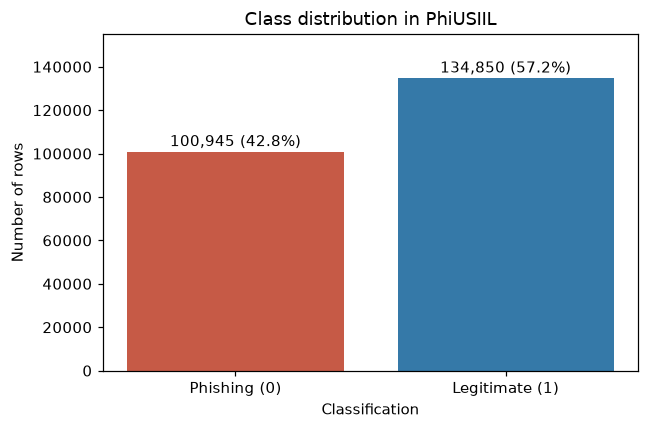

In [4]:
class_counts = df.group_by("label").len().sort("label").with_columns(
    (100 * pl.col("len") / df.height).alias("percent")
)
display(class_counts)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_names, class_counts["len"].to_numpy(), color=colors)
for i, row in enumerate(class_counts.iter_rows(named=True)):
    ax.text(i, row["len"] + 2500, f'{row["len"]:,} ({row["percent"]:.1f}%)', ha="center")
ax.set(title="Class distribution in PhiUSIIL", xlabel="Classification", ylabel="Number of rows", ylim=(0, 155000))
fig.tight_layout()
plt.show()

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

Legitimate rows account for **134,850 (57.2%)**, while phishing rows account for **100,945 (42.8%)**. Both classes are large, but counts alone can exaggerate differences because the legitimate class has more rows. Later comparisons use percentages within each class. These percentages describe this dataset's composition, not the prevalence of phishing on the internet.

## B. Anomaly checks

Counts below refer to rows unless explicitly labeled as distinct URLs or extra occurrences. Checks can overlap, so their counts should not be added together. The original CSV is read only; no observations are dropped or source feature values overwritten.

In [5]:
text_cols = [c for c, dtype in df.schema.items() if dtype == pl.String]
int_cols = [c for c, dtype in df.schema.items() if dtype.is_integer()]
float_cols = [c for c, dtype in df.schema.items() if dtype.is_float()]
binary_cols = ["IsDomainIP", "HasObfuscation", "IsHTTPS", "HasTitle", "HasFavicon",
               "Robots", "IsResponsive", "HasDescription", "HasExternalFormSubmit",
               "HasSocialNet", "HasSubmitButton", "HasHiddenFields", "HasPasswordField",
               "Bank", "Pay", "Crypto", "HasCopyrightInfo", "label"]
ratio_cols = ["CharContinuationRate", "TLDLegitimateProb", "URLCharProb", "ObfuscationRatio",
              "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL"]
score_cols = ["URLSimilarityIndex", "DomainTitleMatchScore", "URLTitleMatchScore"]

print("Text / integer / float columns:", len(text_cols), len(int_cols), len(float_cols))
print("Unexpected remaining dtypes:", {c: str(t) for c, t in df.schema.items()
      if t != pl.String and not t.is_numeric()})
print("Observed binary values:")
for c in binary_cols:
    print(c, df[c].unique().sort().to_list())

audit = df.with_columns(
    pl.col("URL").str.len_chars().alias("URLTextLength"),
    pl.col("URL").str.to_lowercase().str.starts_with("https://").cast(pl.Int64).alias("HTTPSFromURL")
)
url_groups = df.group_by("URL").agg(pl.len().alias("rows"), pl.col("label").n_unique().alias("labels"))
repeated_urls = url_groups.filter(pl.col("rows") > 1)
print("Repeated URL groups:", repeated_urls.height)
print("Rows in repeated URL groups:", repeated_urls["rows"].sum())
print("Extra URL occurrences:", df.height - url_groups.height)
print("Conflicting labels for a URL:", url_groups.filter(pl.col("labels") > 1).height)
print("Extra FILENAME occurrences:", df.height - df["FILENAME"].n_unique())

parse_failures = 0
for url in df["URL"]:
    try:
        parsed = urlsplit(url)
        if parsed.scheme.lower() not in ["http", "https"] or not parsed.hostname:
            parse_failures += 1
    except ValueError:
        parse_failures += 1

checks = [
    ("Any null", pl.any_horizontal(pl.all().is_null())),
    ("Blank text after trimming", pl.any_horizontal([pl.col(c).str.strip_chars() == "" for c in text_cols])),
    ("Leading/trailing text whitespace", pl.any_horizontal([pl.col(c) != pl.col(c).str.strip_chars() for c in text_cols])),
    ("Whitespace inside URL/domain/TLD", pl.any_horizontal([pl.col(c).str.contains(r"\s") for c in ["URL", "Domain", "TLD"]])),
    ("Uppercase domain or TLD", pl.any_horizontal([pl.col(c) != pl.col(c).str.to_lowercase() for c in ["Domain", "TLD"]])),
    ("Binary value outside 0/1", pl.any_horizontal([~pl.col(c).is_in([0, 1]) for c in binary_cols])),
    ("Negative numeric value", pl.any_horizontal([pl.col(c) < 0 for c, t in df.schema.items() if t.is_numeric()])),
    ("Nonfinite float", pl.any_horizontal([~pl.col(c).is_finite() for c in float_cols])),
    ("Ratio/probability outside 0–1", pl.any_horizontal([(pl.col(c) < 0) | (pl.col(c) > 1) for c in ratio_cols])),
    ("Match/similarity score outside 0–100", pl.any_horizontal([(pl.col(c) < 0) | (pl.col(c) > 100) for c in score_cols])),
    ("Nonpositive stored URL/domain/TLD length", pl.any_horizontal([pl.col(c) <= 0 for c in ["URLLength", "DomainLength", "TLDLength"]])),
    ("DomainLength greater than URLLength", pl.col("DomainLength") > pl.col("URLLength")),
    ("Character count greater than URLLength", pl.any_horizontal([pl.col(c) > pl.col("URLLength") for c in ["NoOfLettersInURL", "NoOfDegitsInURL", "NoOfObfuscatedChar"]])),
    ("DomainLength differs from text length", pl.col("DomainLength") != pl.col("Domain").str.len_chars()),
    ("TLDLength differs from text length", pl.col("TLDLength") != pl.col("TLD").str.len_chars()),
    ("URLLength differs from text length", pl.col("URLLength") != pl.col("URLTextLength")),
    ("IsHTTPS differs from URL scheme", pl.col("IsHTTPS") != pl.col("HTTPSFromURL")),
    ("Obfuscation flag/count disagreement", pl.col("HasObfuscation") != (pl.col("NoOfObfuscatedChar") > 0).cast(pl.Int64)),
    ("Title is 0 when HasTitle is 0", (pl.col("Title") == "0") & (pl.col("HasTitle") == 0)),
    ("Title is 0 when HasTitle is 1", (pl.col("Title") == "0") & (pl.col("HasTitle") == 1)),
    ("Uppercase URL characters (informational)", pl.col("URL") != pl.col("URL").str.to_lowercase()),
    ("Possible title encoding damage (pattern screen)", pl.col("Title").str.contains(r"Ã|Â|â€|à¸|à¹|[\x80-\x9f]")),
    ("Title equals na", pl.col("Title").str.to_lowercase() == "na")
]
check_counts = [{"check": name, "affected_rows": audit.select(expr.sum()).item()} for name, expr in checks]
check_counts += [
    {"check": "Exact duplicate rows (all occurrences)", "affected_rows": df.is_duplicated().sum()},
    {"check": "URL parsing / scheme / hostname failure", "affected_rows": parse_failures}
]
display(pl.DataFrame(check_counts))

Text / integer / float columns: 5 41 10
Unexpected remaining dtypes: {}
Observed binary values:
IsDomainIP [0, 1]
HasObfuscation [0, 1]
IsHTTPS [0, 1]
HasTitle [0, 1]
HasFavicon [0, 1]
Robots [0, 1]
IsResponsive [0, 1]
HasDescription [0, 1]
HasExternalFormSubmit [0, 1]
HasSocialNet [0, 1]
HasSubmitButton [0, 1]
HasHiddenFields [0, 1]
HasPasswordField [0, 1]
Bank [0, 1]
Pay [0, 1]
Crypto [0, 1]
HasCopyrightInfo [0, 1]
label [0, 1]
Repeated URL groups: 425
Rows in repeated URL groups: 850
Extra URL occurrences: 425
Conflicting labels for a URL: 0
Extra FILENAME occurrences: 0


check,affected_rows
str,i64
"""Any null""",0
"""Blank text after trimming""",0
"""Leading/trailing text whitespa…",1
"""Whitespace inside URL/domain/T…",0
"""Uppercase domain or TLD""",0
"""Binary value outside 0/1""",0
"""Negative numeric value""",0
"""Nonfinite float""",0
"""Ratio/probability outside 0–1""",0


No nulls, blanks, invalid binary codes, negative numeric values, nonfinite floats, out-of-range ratios/scores, or URL parsing failures were found. Numeric columns have plausible types. The range checks are basic sanity checks, not a complete validation of the original feature extractor.

There are **425 repeated URLs**, involving **850 rows** and **425 extra occurrences**. Their labels agree, and filenames are unique. There are **zero exact duplicate rows**, so these are not identical records. They remain flagged because we lack collection times or enough context to decide which webpage observation to keep.

In [6]:
display(audit.with_columns((pl.col("URLLength") - pl.col("URLTextLength")).alias("length_offset"))
        .group_by("length_offset").len().sort("length_offset"))
display(audit.filter(pl.col("IsHTTPS") != pl.col("HTTPSFromURL"))
        .group_by("label", "IsHTTPS", "HTTPSFromURL").len())

selected_numeric = ["URLLength", "DomainLength", "NoOfSubDomain", "SpacialCharRatioInURL", "LineOfCode"]
numeric_stats = []
for c in selected_numeric:
    numeric_stats.append(df.select(
        pl.lit(c).alias("feature"), pl.col(c).min().alias("min"),
        pl.col(c).quantile(0.25).alias("q25"), pl.col(c).median().alias("median"),
        pl.col(c).quantile(0.75).alias("q75"), pl.col(c).quantile(0.99).alias("p99"),
        pl.col(c).max().alias("max")
    ))
display(pl.concat(numeric_stats, how="vertical_relaxed"))
print("URLLength > pooled p99 (144):", df.filter(pl.col("URLLength") > 144).height)
print("LineOfCode > pooled p99 (10,388):", df.filter(pl.col("LineOfCode") > 10388).height)
print("LargestLineLength maximum:", df["LargestLineLength"].max())

length_offset,len
i64,u32
-35,1
-4,1
-1,187149
0,48644


label,IsHTTPS,HTTPSFromURL,len
i64,i64,i64,u32
0,1,0,493


feature,min,q25,median,q75,p99,max
str,f64,f64,f64,f64,f64,f64
"""URLLength""",13.0,23.0,27.0,34.0,144.0,6097.0
"""DomainLength""",4.0,16.0,20.0,24.0,57.0,110.0
"""NoOfSubDomain""",0.0,1.0,1.0,1.0,3.0,10.0
"""SpacialCharRatioInURL""",0.0,0.038,0.05,0.083,0.158,0.397
"""LineOfCode""",2.0,18.0,429.0,1277.0,10388.0,442666.0


URLLength > pooled p99 (144): 2350
LineOfCode > pooled p99 (10,388): 2357
LargestLineLength maximum: 13975732


| Finding | Affected rows | Decision and reason |
|---|---:|---|
| Repeated URLs | 850 (425 extra) | Kept and flagged; filenames/features differ and labels agree. A sensitivity check follows. |
| Stored URL length differs from displayed text | 187,151 | Kept and flagged. 187,149 are shorter by 1 character; one by 4 and one by 35. This may reflect source preprocessing, which is not verified. Compare with computed text length. |
| HTTPS indicator disagrees with scheme | 493 | Kept and flagged; all have an HTTP URL, `IsHTTPS = 1`, and label 0. The feature's extraction context is unknown. Compare with scheme-derived HTTPS. |
| Possible title encoding damage | 8 | Left flagged; a pattern screen identifies common encoding artifacts, not confirmed corrupt titles. Text repair could change meaning, and title text is not plotted. |
| Leading/trailing title whitespace | 1 | Left flagged; title text is not used in the selected plots. |
| Title `0` with `HasTitle = 0` | 32,714 | Kept as a structural absence marker, not treated as an ordinary title or a null. |
| Title `0` with `HasTitle = 1` | 5 | Left flagged as ambiguous; a literal title is possible, so no replacement. |
| Title `na` with `HasTitle = 1` | 5 | Left flagged as ambiguous text, not automatically converted to missing. |
| Stored URL length above pooled 99th percentile (144) | 2,350 | Kept; unusually long URLs are possible. This is a tail screen, not proof of error. |
| Lines of code above pooled 99th percentile (10,388) | 2,357 | Kept; large webpages are possible. Use a log scale. |

`LargestLineLength` reaches 13,975,732; a large minified line is possible, so the maximum is not used to declare invalid rows. Domain and TLD lengths agree with their strings. Two URLs contain uppercase characters, but URL paths can be case sensitive; this is not treated as an error or normalized. Nothing is fixed or dropped because the ambiguous cases do not justify inventing replacement values.

In [7]:
sensitivity = audit.group_by("label").agg(
    pl.len().alias("rows"), pl.col("URLLength").median().alias("stored_length_median"),
    pl.col("URLTextLength").median().alias("text_length_median"),
    (100 * pl.col("IsHTTPS").mean()).alias("stored_HTTPS_pct"),
    (100 * pl.col("HTTPSFromURL").mean()).alias("scheme_HTTPS_pct")
).sort("label")
display(sensitivity)
# Keep the first CSV occurrence only for this comparison, not for the main analysis.
dedup = audit.unique(subset=["URL"], keep="first", maintain_order=True)
display(dedup.group_by("label").agg(
    pl.len().alias("unique_URLs"), pl.col("URLLength").median().alias("length_median"),
    (100 * pl.col("IsHTTPS").mean()).alias("HTTPS_pct"),
    (100 * pl.col("HasPasswordField").mean()).alias("password_field_pct"),
    (100 * pl.col("HasExternalFormSubmit").mean()).alias("external_form_pct")
).sort("label"))

label,rows,stored_length_median,text_length_median,stored_HTTPS_pct,scheme_HTTPS_pct
i64,u32,f64,f64,f64,f64
0,100945,34.0,34.0,49.223835,48.73545
1,134850,26.0,27.0,100.0,100.0


label,unique_URLs,length_median,HTTPS_pct,password_field_pct,external_form_pct
i64,u32,f64,f64,f64,f64
0,100520,34.0,49.122563,5.330283,0.426781
1,134850,26.0,100.0,13.848721,7.371895


Computed text-length medians are **34 (phishing) and 27 (legitimate)**, compared with stored medians of **34 and 26**. The phishing HTTPS percentage is **49.22%** using `IsHTTPS` and **48.74%** using the URL scheme; both versions give 100% for legitimate rows. The basic directions remain the same.

Keeping only the first occurrence of each URL leaves 100,520 phishing and 134,850 legitimate URLs. Phishing HTTPS is 49.12%, password fields 5.33%, and external form submission 0.43%. These are close to the full-data values reported below; the main plots still use all original rows.

## C. Feature distributions

Selected features cover URL length, domain structure, HTTPS, URL obfuscation, and webpage behavior. Counts use all rows. Log scales show tails without removing observations.

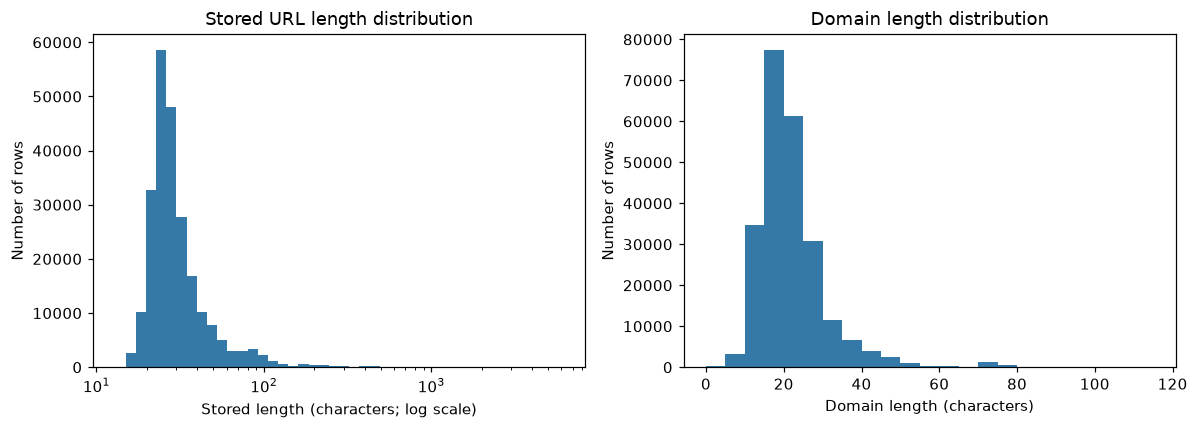

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature, title in zip(axes, ["URLLength", "DomainLength"],
                             ["Stored URL length distribution", "Domain length distribution"]):
    values = df[feature].to_numpy()
    if feature == "URLLength":
        ax.hist(values, bins=np.geomspace(values.min(), values.max() + 1, 45), color="#3579a8")
        ax.set_xscale("log")
        ax.set_xlabel("Stored length (characters; log scale)")
    else:
        ax.hist(values, bins=np.arange(0, 116, 5), color="#3579a8")
        ax.set_xlabel("Domain length (characters)")
    ax.set(title=title, ylabel="Number of rows")
fig.tight_layout()
plt.show()

URL length has a strong right tail: the median is **27**, the middle half spans **23–34**, and the maximum is **6,097**. The log x-axis has unequal character-width bins; the bars show counts per bin, not density per character. Domain length is less spread out, with a median of **20**, an interquartile range of **16–24**, and a maximum of **110**. The URL-length plot uses the stored feature despite its flagged text-length offsets.

NoOfSubDomain,len
i64,u32
0,13983
1,178406
2,36353
3,5119
4,1563
5,336
6,21
7,5
8,4


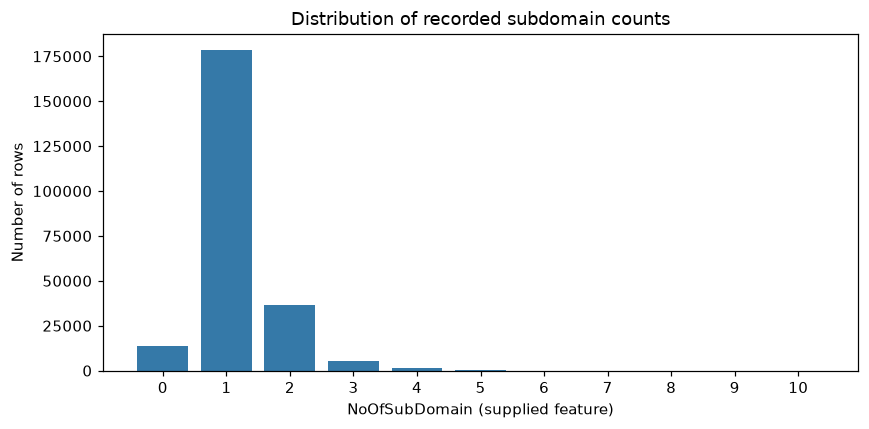

In [9]:
subdomain_counts = df.group_by("NoOfSubDomain").len().sort("NoOfSubDomain")
display(subdomain_counts)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(subdomain_counts["NoOfSubDomain"].to_numpy(), subdomain_counts["len"].to_numpy(), color="#3579a8")
ax.set(title="Distribution of recorded subdomain counts", xlabel="NoOfSubDomain (supplied feature)", ylabel="Number of rows")
ax.set_xticks(range(11))
fig.tight_layout()
plt.show()

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

One recorded subdomain is the most common value: **178,406 rows (75.7%)**. The median and both quartiles are 1, but the tail reaches 10. The dataset's counting convention is retained; no new subdomain count is inferred from dots, since multi-part domain suffixes can make that misleading.

feature,present_rows,present_pct
str,i64,f64
"""IsHTTPS""",184539,78.262474
"""HasObfuscation""",485,0.205687
"""IsDomainIP""",638,0.270574
"""NoOfURLRedirect""",31464,13.343794
"""HasPasswordField""",24113,10.226256
"""HasExternalFormSubmit""",10372,4.398736


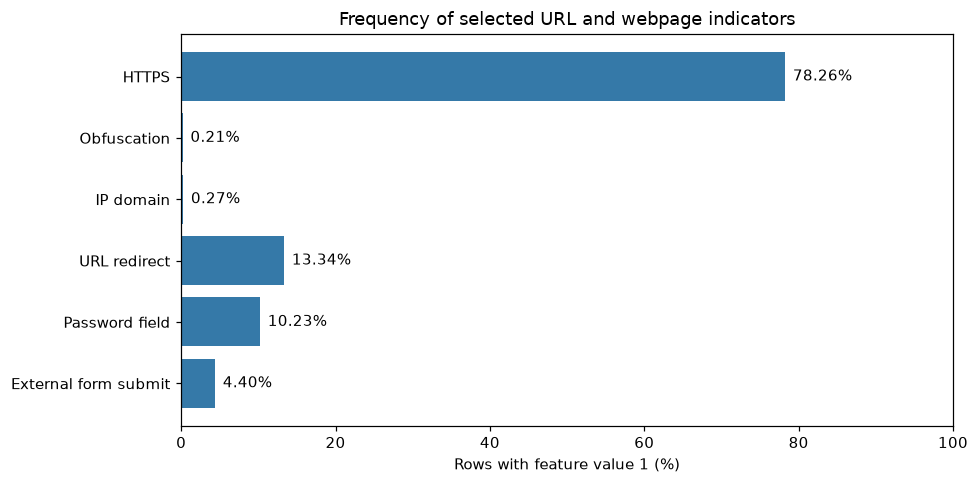

In [10]:
binary_features = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "NoOfURLRedirect", "HasPasswordField", "HasExternalFormSubmit"]
binary_labels = ["HTTPS", "Obfuscation", "IP domain", "URL redirect", "Password field", "External form submit"]
binary_summary = df.select([pl.col(c).sum().alias(c) for c in binary_features]).transpose(
    include_header=True, header_name="feature", column_names=["present_rows"]
).with_columns((100 * pl.col("present_rows") / df.height).alias("present_pct"))
display(binary_summary)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(binary_labels[::-1], binary_summary["present_pct"].to_numpy()[::-1], color="#3579a8")
for i, pct in enumerate(binary_summary["present_pct"].to_numpy()[::-1]):
    ax.text(pct + 1, i, f"{pct:.2f}%", va="center")
ax.set(title="Frequency of selected URL and webpage indicators", xlabel="Rows with feature value 1 (%)", xlim=(0, 100))
fig.tight_layout()
plt.show()

HTTPS is common (**78.26%**), while obfuscation (**0.21%**) and IP-based domains (**0.27%**) are rare. Password fields appear in **10.23%** of rows and external form submission in **4.40%**. These indicators are mostly zero except HTTPS. `NoOfURLRedirect` takes only 0 and 1 in this file (**13.34%** are 1), so it is plotted as an indicator rather than as a broad count distribution.

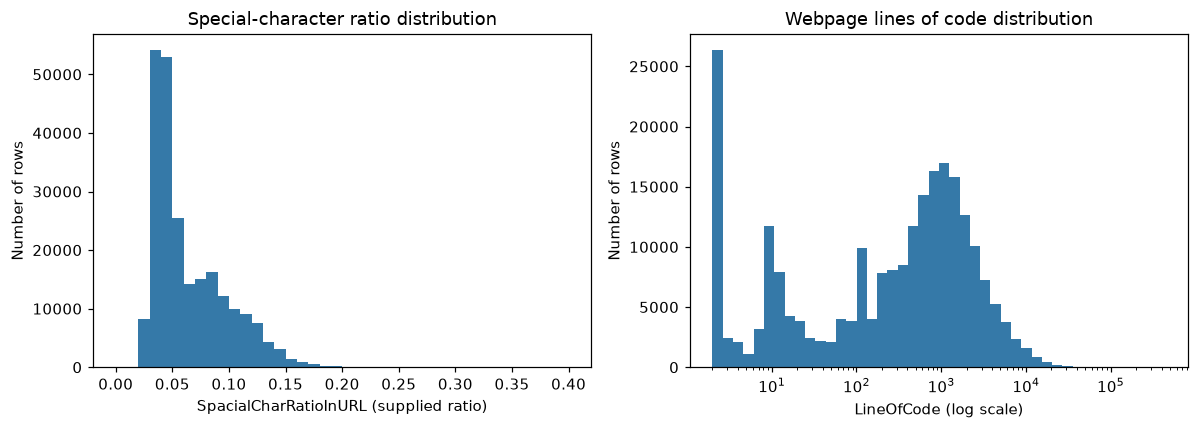

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["SpacialCharRatioInURL"].to_numpy(), bins=np.linspace(0, 0.4, 41), color="#3579a8")
axes[0].set(title="Special-character ratio distribution", xlabel="SpacialCharRatioInURL (supplied ratio)", ylabel="Number of rows")
values = df["LineOfCode"].to_numpy()
axes[1].hist(values, bins=np.geomspace(values.min(), values.max() + 1, 45), color="#3579a8")
axes[1].set_xscale("log")
axes[1].set(title="Webpage lines of code distribution", xlabel="LineOfCode (log scale)", ylabel="Number of rows")
fig.tight_layout()
plt.show()

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

The special-character ratio centers around **0.05**, with the middle half between **0.038 and 0.083** and a tail up to **0.397**. Lines of code are much more spread out: the median is **429**, the interquartile range is **18–1,277**, and the maximum is **442,666**. The page-size histogram has a large spike at very low values and a broad concentration in the hundreds to thousands. The log scale includes the whole range, with counts per unequal-width bin. Neither special characters nor page size alone establishes phishing.

## D. Feature relationships

All class percentages below use the class's full row count as the denominator (100,945 phishing and 134,850 legitimate). They describe how common a feature is **within a class**, not the probability that a website is phishing given that feature.

feature,label,rows,mean,q25,median,q75,max
str,i64,u32,f64,f64,f64,f64,f64
"""DomainLength""",0,100945,24.465144,16.0,22.0,29.0,110.0
"""DomainLength""",1,134850,19.22861,16.0,19.0,22.0,50.0
"""LineOfCode""",0,100945,65.730467,2.0,12.0,90.0,29687.0
"""LineOfCode""",1,134850,1947.49168,613.0,1105.0,2088.0,442666.0
"""NoOfSubDomain""",0,100945,1.168894,1.0,1.0,1.0,10.0
"""NoOfSubDomain""",1,134850,1.161661,1.0,1.0,1.0,4.0
"""SpacialCharRatioInURL""",0,100945,0.083285,0.051,0.08,0.111,0.397
"""SpacialCharRatioInURL""",1,134850,0.048356,0.036,0.042,0.053,0.231
"""URLLength""",0,100945,45.720293,26.0,34.0,48.0,6097.0


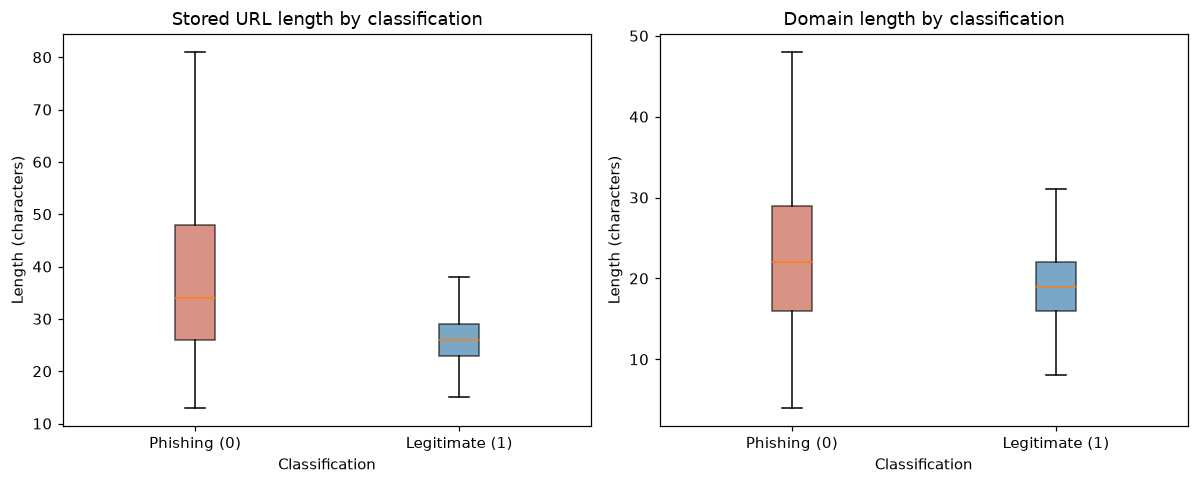

In [12]:
class_stats = []
for c in selected_numeric:
    class_stats.append(df.group_by("label").agg(
        pl.len().alias("rows"), pl.col(c).mean().alias("mean"),
        pl.col(c).quantile(0.25).alias("q25"), pl.col(c).median().alias("median"),
        pl.col(c).quantile(0.75).alias("q75"), pl.col(c).max().alias("max")
    ).with_columns(pl.lit(c).alias("feature")).select("feature", "label", "rows", "mean", "q25", "median", "q75", "max"))
display(pl.concat(class_stats, how="vertical_relaxed").sort("feature", "label"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, feature, title in zip(axes, ["URLLength", "DomainLength"],
                             ["Stored URL length by classification", "Domain length by classification"]):
    groups = [df.filter(pl.col("label") == label)[feature].to_numpy() for label in [0, 1]]
    boxes = ax.boxplot(groups, tick_labels=class_names, showfliers=False, patch_artist=True)
    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    ax.set(title=title, xlabel="Classification", ylabel="Length (characters)")
fig.tight_layout()
plt.show()

### Relationship 1: URL and domain lengths by classification

**So what?** Phishing URLs have a median stored length of **34** (middle half **26–48**), compared with **26** (**23–29**) for legitimate URLs. Domain medians are **22 versus 19**, with middle halves of **16–29 versus 16–22**. Longer, more variable phishing URLs fit the expected pattern, but the overlapping boxes show that short URLs are not enough to identify legitimacy. Outlier markers are hidden for readability; no rows were removed, and the tables and Section C show the full ranges. This agrees with the teammate's existing URL-length observation and adds the domain comparison.

**What next?** Compare URL length within domain-length ranges to see whether the difference mainly comes from the hostname or additional paths and query strings. Use computed text lengths as a sensitivity check before defining any cutoffs.

label,subdomain_group,len,class_rows,percent
i64,str,u32,u32,f64
0,"""0""",13983,100945,13.852098
0,"""1""",63545,100945,62.950121
0,"""2""",18115,100945,17.945416
0,"""3+""",5302,100945,5.252365
1,"""1""",114861,134850,85.176863
1,"""2""",18238,134850,13.524657
1,"""3+""",1751,134850,1.29848


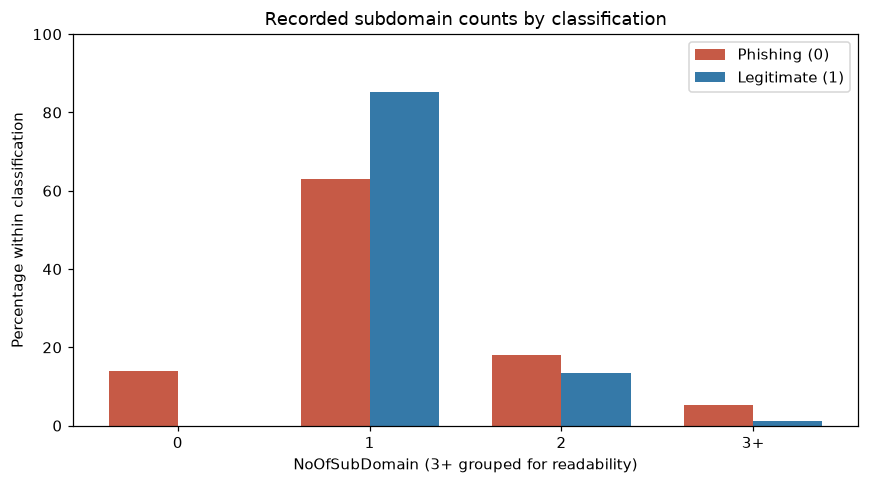

In [13]:
subdomains = df.with_columns(
    pl.when(pl.col("NoOfSubDomain") >= 3).then(pl.lit("3+"))
    .otherwise(pl.col("NoOfSubDomain").cast(pl.String)).alias("subdomain_group")
)
subdomain_rates = subdomains.group_by("label", "subdomain_group").len().join(
    class_counts.select("label", pl.col("len").alias("class_rows")), on="label"
).with_columns((100 * pl.col("len") / pl.col("class_rows")).alias("percent")).sort("label", "subdomain_group")
display(subdomain_rates)
fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ["0", "1", "2", "3+"]
x = np.arange(len(categories))
for label, name, color, offset in zip([0, 1], class_names, colors, [-0.18, 0.18]):
    rates = subdomain_rates.filter(pl.col("label") == label)
    values = [rates.filter(pl.col("subdomain_group") == category)["percent"].item()
              if rates.filter(pl.col("subdomain_group") == category).height else 0 for category in categories]
    ax.bar(x + offset, values, width=0.36, label=name, color=color)
ax.set_xticks(x, categories)
ax.set(title="Recorded subdomain counts by classification", xlabel="NoOfSubDomain (3+ grouped for readability)", ylabel="Percentage within classification", ylim=(0, 100))
ax.legend()
fig.tight_layout()
plt.show()

### Relationship 2: Recorded subdomain counts by classification

**So what?** Both classes are concentrated at one subdomain, but the percentages differ: **63.0%** of phishing rows and **85.2%** of legitimate rows. Three or more occur in **5.3% versus 1.3%**. Surprisingly, all **13,983** zero-subdomain rows are phishing in this sample, while mean counts are almost equal (**1.169 versus 1.162**). Looking only at the mean would miss these differences. The patterns could reflect collection or extraction conventions; they do not show which domain structures confuse people.

**What next?** Inspect examples and confirm the source's subdomain counting rule, especially for zero-count rows. Then compare these groups within HTTPS and domain-length categories.

label,class_rows,IsHTTPS,HasObfuscation,IsDomainIP,NoOfURLRedirect,HasPasswordField,HasExternalFormSubmit
i64,u32,f64,f64,f64,f64,f64,f64
0,100945,49.223835,0.48046,0.632027,15.169647,5.387092,0.426965
1,134850,100.0,0.0,0.0,11.977011,13.848721,7.371895


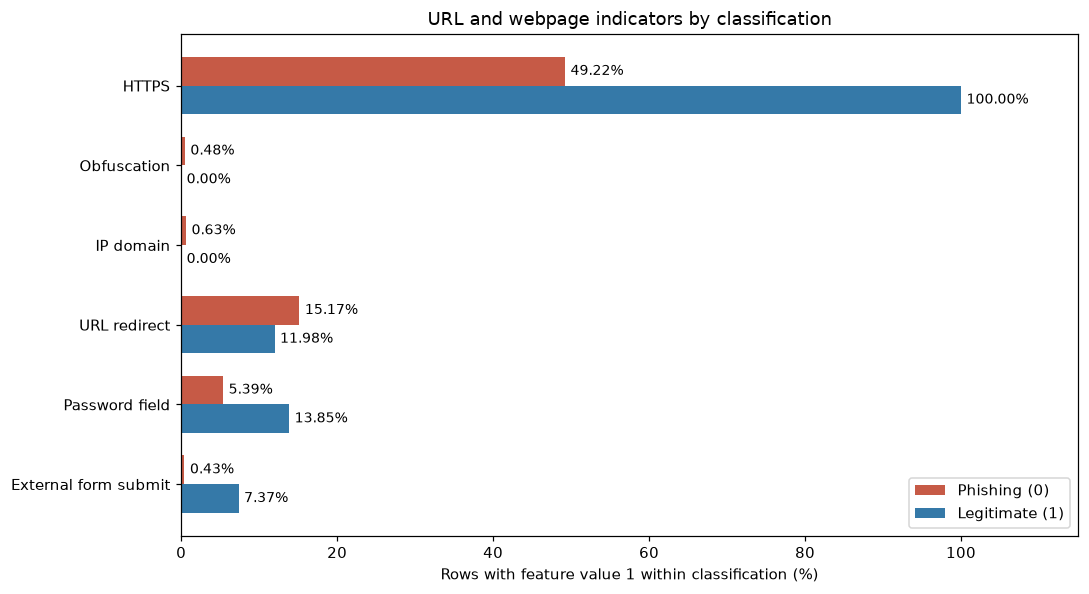

In [14]:
class_binary = df.group_by("label").agg(
    pl.len().alias("class_rows"), *[(100 * pl.col(c).mean()).alias(c) for c in binary_features]
).sort("label")
display(class_binary)
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(binary_features))
for label, name, color, offset in zip([0, 1], class_names, colors, [-0.18, 0.18]):
    values = class_binary.filter(pl.col("label") == label).select(binary_features).row(0)
    bars = ax.barh(y + offset, values, height=0.36, label=name, color=color)
    for bar, value in zip(bars, values):
        ax.text(value + 0.7, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center", fontsize=9)
ax.set_yticks(y, binary_labels)
ax.invert_yaxis()
ax.set(title="URL and webpage indicators by classification", xlabel="Rows with feature value 1 within classification (%)", xlim=(0, 115))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Relationship 3: URL and webpage indicators by classification

**So what?** HTTPS occurs in **49.22% of phishing rows and 100% of legitimate rows**. It separates groups here, but nearly half of phishing rows also have it, so HTTPS alone is not a reliable legitimacy signal. Obfuscation (**0.48%**) and IP domains (**0.63%**) occur only in phishing rows, but their rarity means they describe very few phishing examples. Unexpectedly, password fields (**5.39% versus 13.85%**) and external form submission (**0.43% versus 7.37%**) are more common among legitimate rows. Legitimate sites also use forms; these features should not be treated as automatic warning signs. Recorded redirects occur in **15.17% versus 11.98%**, a smaller difference; their 0/1 encoding does not measure redirect-chain length.

**What next?** Examine form features among HTTPS-only rows and within webpage-size groups. The table above shows a page-size median of **12 lines for phishing versus 1,105 for legitimate**, so extraction or collection differences may contribute to the form patterns. Any class activity should test whether visible HTTPS cues affect recognition while controlling the other features; participants cannot necessarily see source-code features directly.

## E. Research question reflection

**Original question:** Which features of phishing links and webpages make them harder for people to recognize?

The dataset supports a narrower technical question: **Which URL and webpage characteristics differ between phishing and legitimate rows in PhiUSIIL, especially when phishing rows also have HTTPS or ordinary-looking domain structures?**

The exploratory results suggest useful examples to investigate, rather than an answer about human recognition. Many phishing rows have HTTPS, a single recorded subdomain, and URL lengths overlapping legitimate rows. Meanwhile, forms appear more often in legitimate rows here. These patterns make combinations and context worth studying. They do not prove that any feature causes people to be fooled.

For the proposed class activity, the group could compare recognition accuracy for phishing examples with and without visible HTTPS or different URL structures, using otherwise comparable examples. Webpage appearance would need screenshots or a separate controlled setup because this CSV contains extracted characteristics, not what participants saw. No recognition scores or participant responses are present in this dataset.

Follow-up work should verify feature extraction conventions, check combinations within HTTPS and page-size subgroups, and later see whether patterns hold in the teammates' datasets. This notebook does not join datasets, train models, or produce the unified group report. The repeated URLs, feature inconsistencies, and different collection sources limit how far these findings can be generalized.

## Secondary

The cells below are retained from the original notebook and executed in this combined analysis.

# Exploratory Data Analysis: Website Phishing Dataset

## CS 418 - Checkpoint 3

In this notebook, it will explore the UCI Website Phishing dataset to identify patterns in phishing-related website features.

Our research question is:
**Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?**

We will examine feature distributions, missing values, anomalies, and relationships between website characteristics and phishing classifications.

In [1]:
import pandas as pd
from scipy.io import arff
from pathlib import Path

data_path = Path("../datasets/website-phishing/PhishingData.arff")

data, metadata = arff.loadarff(data_path)

df = pd.DataFrame(data)

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.decode("utf-8")

df.head()

,SFH,popUpWidnow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
0,1,-1,1,-1,-1,1,1,1,0,0
1,-1,-1,-1,-1,-1,0,1,1,1,1
2,1,-1,0,0,-1,0,-1,1,0,1
3,1,0,1,-1,-1,0,1,1,0,0
4,-1,-1,1,-1,0,0,-1,1,0,1


### 1. Dataset Profile
In this section, it examines the size, data types, missing values, and summary statistics of the UCI Phishing dataset.

In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe(include="all"))

Dataset Shape:
(1353, 10)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 1353 entries, 0 to 1352
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SFH                1353 non-null   str  
 1   popUpWidnow        1353 non-null   str  
 2   SSLfinal_State     1353 non-null   str  
 3   Request_URL        1353 non-null   str  
 4   URL_of_Anchor      1353 non-null   str  
 5   web_traffic        1353 non-null   str  
 6   URL_Length         1353 non-null   str  
 7   age_of_domain      1353 non-null   str  
 8   having_IP_Address  1353 non-null   str  
 9   Result             1353 non-null   str  
dtypes: str(10)
memory usage: 123.5 KB

Missing Values:
SFH                  0
popUpWidnow          0
SSLfinal_State       0
Request_URL          0
URL_of_Anchor        0
web_traffic          0
URL_Length           0
age_of_domain        0
having_IP_Address    0
Result               0
dtype: int64

Summa

,SFH,popUpWidnow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
count,1353,1353,1353,1353,1353,1353,1353,1353,1353,1353
unique,3,3,3,3,3,3,3,2,2,3
top,1,0,1,-1,-1,0,0,1,0,-1
freq,767,639,751,617,610,473,563,825,1198,702


### Dataset Profile Findings

In the UCI Website Phishing, the dataset contains 1,353 rows and 10 columns, which includes nine phishing-related features, as well as one classification column (Result).

There are no missing values from this dataset. Although, all the columns were initially loaded as strings, even though the features use numerical codes like -1, 0, and 1.

In the dataset, it also has an odd distribution of classifications, with 702 phishing websites, 103 suspcious websites, and 548 legitimate websites.

Overvall, the dataset shows as completed, but the feature values need to be converted into numerical categories before continuing the analysis.

In [ ]:
df = df.astype(int)

print("Duplicate rows:", df.duplicated().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nUnique values by column:")
for col in df.columns:
    print(col, sorted(df[col].unique()))

print("\nUpdated data types:")
print(df.dtypes)

Duplicate rows: 629

Total missing values: 0

Unique values by column:
SFH [np.int64(-1), np.int64(0), np.int64(1)]
popUpWidnow [np.int64(-1), np.int64(0), np.int64(1)]
SSLfinal_State [np.int64(-1), np.int64(0), np.int64(1)]
Request_URL [np.int64(-1), np.int64(0), np.int64(1)]
URL_of_Anchor [np.int64(-1), np.int64(0), np.int64(1)]
web_traffic [np.int64(-1), np.int64(0), np.int64(1)]
URL_Length [np.int64(-1), np.int64(0), np.int64(1)]
age_of_domain [np.int64(-1), np.int64(1)]
having_IP_Address [np.int64(0), np.int64(1)]
Result [np.int64(-1), np.int64(0), np.int64(1)]

Updated data types:
SFH                  int64
popUpWidnow          int64
SSLfinal_State       int64
Request_URL          int64
URL_of_Anchor        int64
web_traffic          int64
URL_Length           int64
age_of_domain        int64
having_IP_Address    int64
Result               int64
dtype: object


### Anomaly Detection Findings
After checking the dataset, I found 629 duplicate rows and no missing values. All 1,353 rows initially contained string values, so I converted the columns into integers to make them easier to analyze. 

Some of the features contain categorical codes such as -1, 0, and 1. I did not find values that are outside these codes, although the valid categoires still need to be reviewed against the dataset documentation.

I have decided to keep the duplicate rows because multiple websites could potentially share the same phishing related characteristics. However, I did flag them as posssible limitations since the dataset does not include individual website IDs to verify if they are actually duplicate observations.

Matplotlib is building the font cache; this may take a moment.


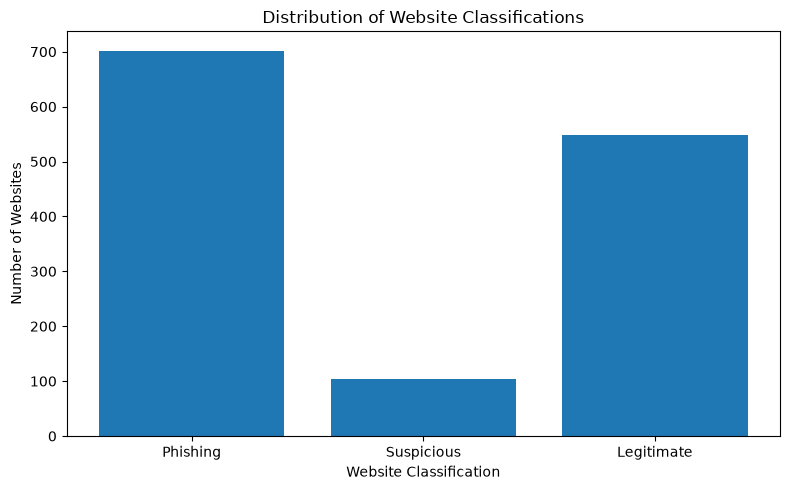

In [ ]:
import matplotlib.pyplot as plt

result_counts = df["Result"].value_counts().reindex([-1, 0, 1], fill_value=0)

labels = ["Phishing", "Suspicious", "Legitimate"]

plt.figure(figsize=(8, 5))
plt.bar(labels, result_counts.values)

plt.title("Distribution of Website Classifications")
plt.xlabel("Website Classification")
plt.ylabel("Number of Websites")

plt.tight_layout()
plt.show()

### Distribution of Website Classifications

In the graph above, it shows that phishing websites make up the largest category with 702 observations, followed by 548 legitimate websites and 103 suspicious websites. In the dataset, it contains the least amount of suspicious websites compared to the other two categories. This is important because the smaller number of suspicious websites may make it harder to identify patterns for that group.

This graph gives us a starting point for comparing phishing-related features across the three classifications.

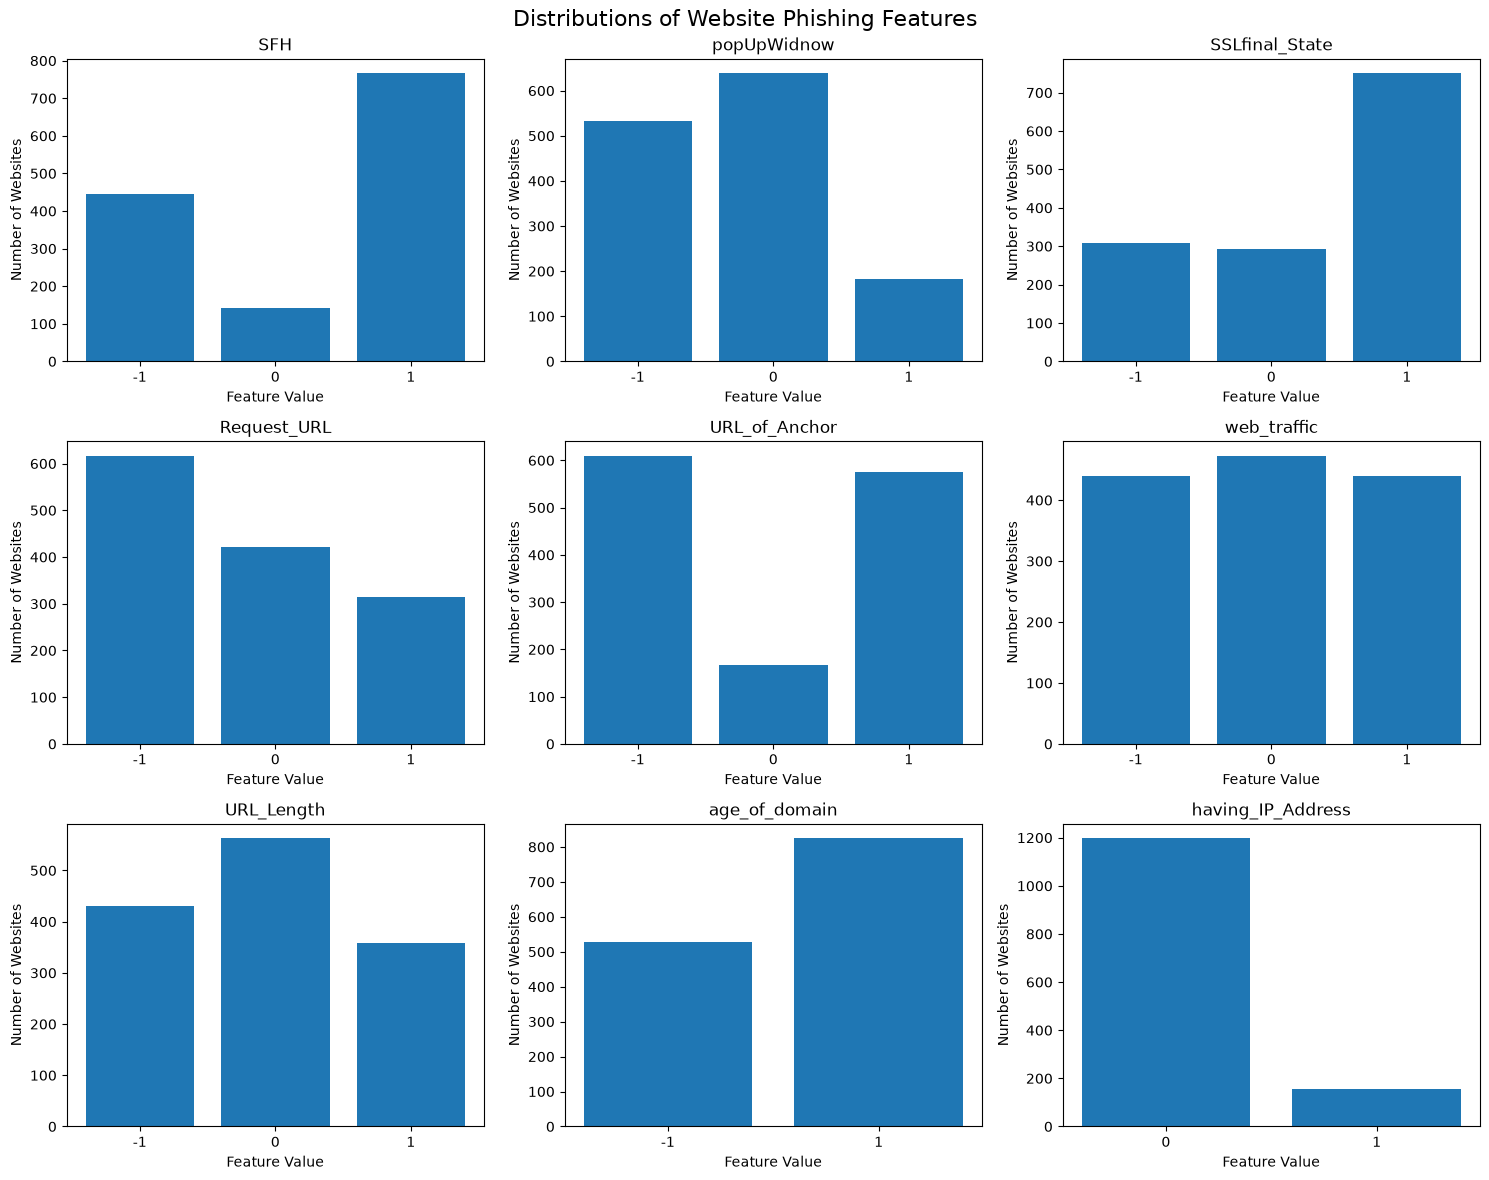

In [ ]:
features = [col for col in df.columns if col != "Result"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, feature in zip(axes.flat, features):
    counts = df[feature].value_counts().sort_index()

    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Number of Websites")

plt.suptitle("Distributions of Website Phishing Features", fontsize=16)
plt.tight_layout()
plt.show()

### Distribution of Phishing Features
In the graph, it shows how the nine phishing-related features are distributed across the 1,353 websites. Some features have odd distributions. An example of this would be: having_IP_Address is mostly 0, while SSLfinal_State and SFH have more observations with a value of 1.

Other features, such as web_traffic have a more even distribution across their categories. URL_of_Anchor also stands out because values -1 and 1 are much more than commmon than 0. 

These findings show that some website characteristics appear more often than others. But, we still need to compare them with the website classifications to determine whether they are associated with phishing.

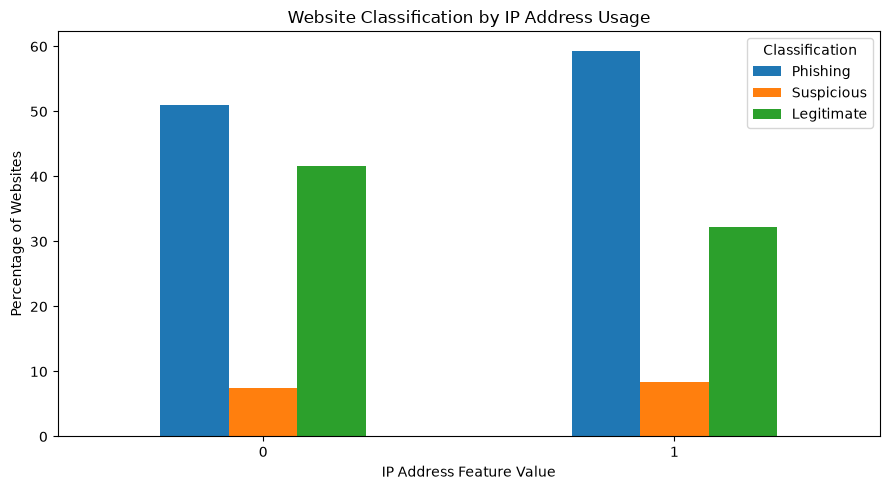

In [ ]:
# this is the relationship between IP address usage and website classification
ip_result = pd.crosstab(
    df["having_IP_Address"],
    df["Result"],
    normalize="index"
) * 100

ip_result = ip_result.reindex(columns=[-1, 0, 1], fill_value=0)

ip_result.columns = ["Phishing", "Suspicious", "Legitimate"]
ip_result.index = ip_result.index.astype(str)

ip_result.plot(kind="bar", figsize=(9, 5))

plt.title("Website Classification by IP Address Usage")
plt.xlabel("IP Address Feature Value")
plt.ylabel("Percentage of Websites")
plt.xticks(rotation=0)
plt.legend(title="Classification")
plt.tight_layout()
plt.show()

### Relationship 1: IP Address Feature vs. Website Classification

What the graph shows:

Websites with an IP address feature value of 1 have a higher percentage of phishing classifications (about 59%) compared to websites with a value of 0 (about 51%).

So what?:

This potentially means that the IP address feature may be associated with whether a website is classified as phishing. This pattern is somewhat expected because unusual URL characteristics can be signs of phishing. However, both groups still contain legitimate websites, so this feature alone is not enough to identify phishing.

What next?:

Next, we could compare the IP address feature with other characteristics, such as SSL status or URL length, to see whether combining multiple features helps distinguish phishing websites from legitimate ones. We should also compare this finding with our primary phishing dataset.

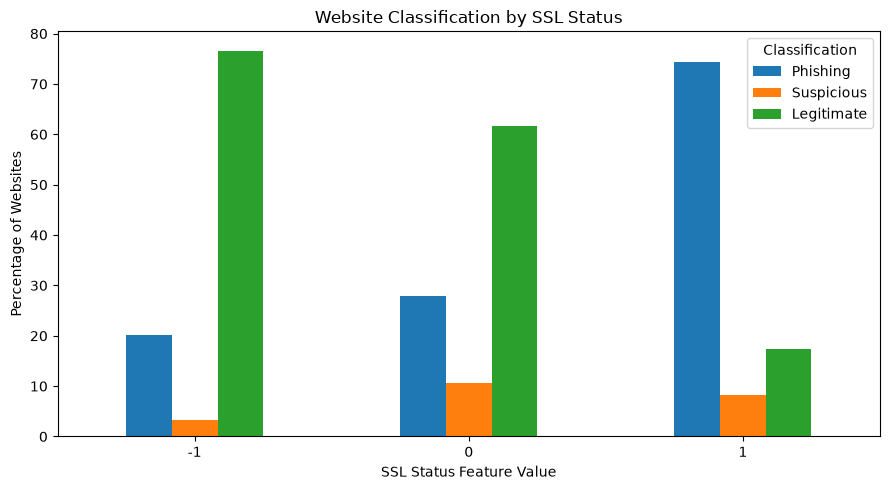

In [ ]:
# here lies the relationship between SSL status and website classification
ssl_result = pd.crosstab(
    df["SSLfinal_State"],
    df["Result"],
    normalize="index"
) * 100

ssl_result = ssl_result.reindex(
    index=[-1, 0, 1],
    columns=[-1, 0, 1],
    fill_value=0
)

ssl_result.columns = ["Phishing", "Suspicious", "Legitimate"]
ssl_result.index = ssl_result.index.astype(str)

ssl_result.plot(kind="bar", figsize=(9, 5))

plt.title("Website Classification by SSL Status")
plt.xlabel("SSL Status Feature Value")
plt.ylabel("Percentage of Websites")
plt.xticks(rotation=0)
plt.legend(title="Classification")
plt.tight_layout()
plt.show()

### Relationship 2: SSL Status vs. Website Classification

What the graph shows:

The graph shows a big difference in website classifications depending on SSL status. Around 74% of websites with an SSL feature value of 1 are classified as phishing, compared to about 20% of websites with a value of -1.

So what?:

This potentially means that SSL status is strongly associated with phishing classification in this dataset. The difference was interesting because it is much larger than the difference observed in the IP address comparison. But, we need to confirm what the SSL category values represent before drawing conclusions about website security.

What next?:

Next, we could compare SSL status with other phishing indicators, such as URL length or domain age, to see whether these characteristics show similar patterns. We could also see whether this relationship appears in our primary phishing dataset.

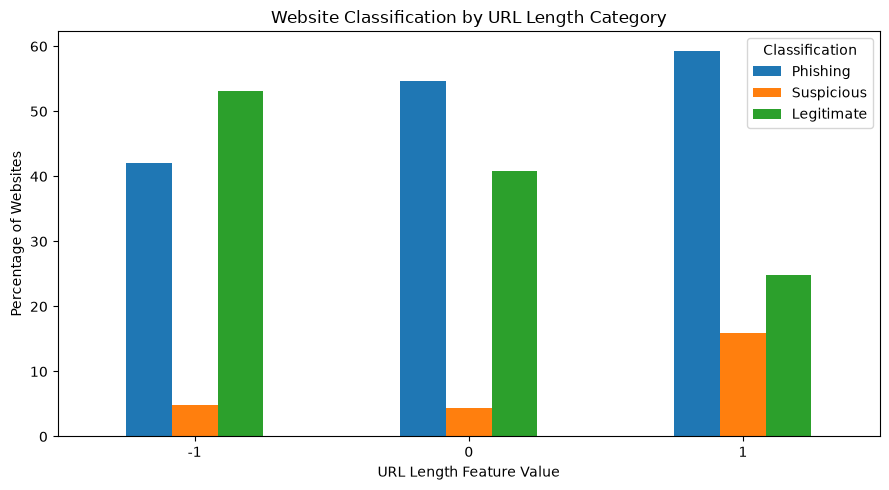

In [ ]:
# here lies the relationship between URL length and website classification

length_result = pd.crosstab(
    df["URL_Length"],
    df["Result"],
    normalize="index"
) * 100

length_result = length_result.reindex(
    index=[-1, 0, 1],
    columns=[-1, 0, 1],
    fill_value=0
)

length_result.columns = ["Phishing", "Suspicious", "Legitimate"]
length_result.index = length_result.index.astype(str)

length_result.plot(kind="bar", figsize=(9, 5))

plt.title("Website Classification by URL Length Category")
plt.xlabel("URL Length Feature Value")
plt.ylabel("Percentage of Websites")
plt.xticks(rotation=0)
plt.legend(title="Classification")
plt.tight_layout()
plt.show()

### Relationship 3: URL Length vs. Website Classification

What the graph shows:

In this graph, it shows that website classification differs across URL length categories. Around 42% of websites in category -1 are classified as phishing, compared to about 55% in category 0 and 59% in category 1.

So what?:

This potentially means that URL length categories may be associated with phishing classification. The pattern was somewhat expected because unusual URL structures can be common in phishing websites. But, the dataset uses categorical codes instead of actual URL lengths, so we need to verify what each category represents before drawing conclusions about longer or shorter URLs.

What next?:

Next, we could compare URL length with other phishing signs, such as SSL status and domain age, to see if combining these characteristics reveals stronger patterns. We could also compare the URL length findings against our primary PhiUSIIL dataset to see if the relationship is consistent across both datasets.

## 4. Comparison with Primary Dataset

In this section, we will compare URL length and phishing classification patterns between the UCI Website Phishing secondary dataset and the PhiUSIIL Phishing URL dataset.

Since the datasets represent URL length differently, we will analyze them separately and compare their patterns rather than directly joining observations.

In [ ]:
primary_path = Path("../datasets/PhiUSIIL_Phishing_URL_Dataset.csv")

primary_df = pd.read_csv(primary_path)

print("Primary Dataset Shape:")
print(primary_df.shape)

print("\nPrimary Dataset Columns:")
print(primary_df.columns.tolist())

display(primary_df.head())

Primary Dataset Shape:
(235795, 56)

Primary Dataset Columns:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [ ]:
# checking classification counts in the primary dataset
print("Primary Dataset Classification Counts:")
print(primary_df["label"].value_counts().sort_index())

# checking URL length statistics by classification
print("\nURL Length Statistics by Classification:")
display(primary_df.groupby("label")["URLLength"].describe())

Primary Dataset Classification Counts:
label
0    100945
1    134850
Name: count, dtype: int64

URL Length Statistics by Classification:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100945.0,45.720293,61.145523,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.228610,4.815612,15.0,23.0,26.0,29.0,57.0


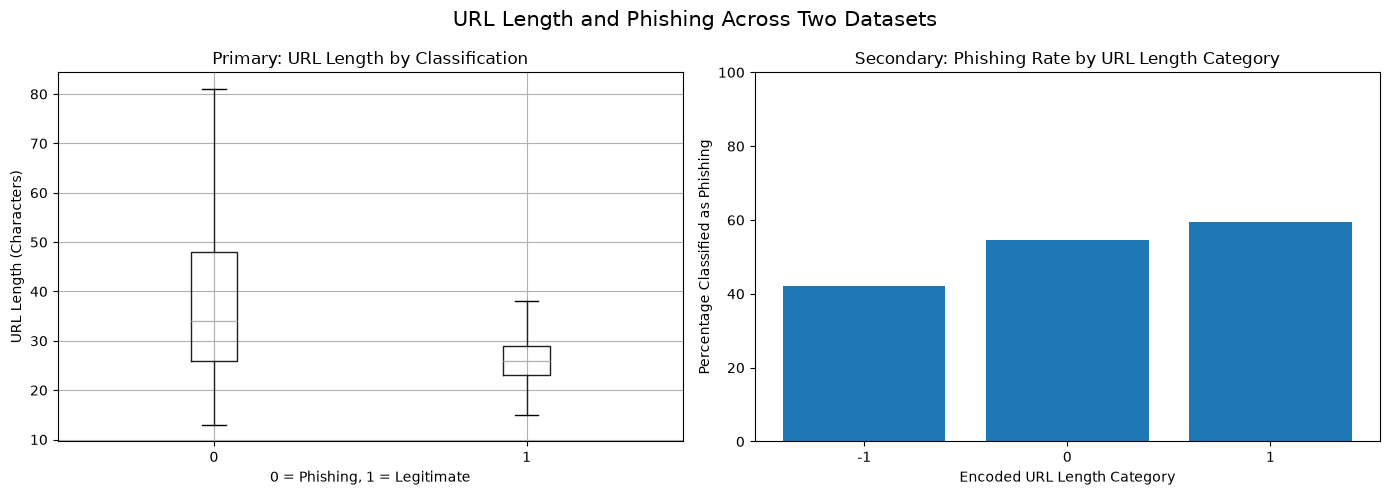

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

primary_df.boxplot(
    column="URLLength",
    by="label",
    ax=axes[0],
    showfliers=False
)

axes[0].set_title("Primary: URL Length by Classification")
axes[0].set_xlabel("0 = Phishing, 1 = Legitimate")
axes[0].set_ylabel("URL Length (Characters)")

secondary_rates = (
    df.groupby("URL_Length")["Result"]
    .apply(lambda x: (x == -1).mean() * 100)
    .reindex([-1, 0, 1])
)

axes[1].bar(
    secondary_rates.index.astype(str),
    secondary_rates.values
)

axes[1].set_title("Secondary: Phishing Rate by URL Length Category")
axes[1].set_xlabel("Encoded URL Length Category")
axes[1].set_ylabel("Percentage Classified as Phishing")
axes[1].set_ylim(0, 100)

plt.suptitle("URL Length and Phishing Across Two Datasets", fontsize=15)
plt.tight_layout()
plt.show()

### Cross-Dataset Comparison Findings

What the graph shows:

In the primary PhiUSIIL dataset, it shows that phishing websites usually have longer URLs than legitimate websites. The median phishing URL length is 34 characters, compared to 26 characters for legitimate websites.

In the secondary Website Phishing dataset, it also shows differences in phishing classification across URL length categories. Phishing classifications increase from approximately 42% in category -1 to 59% in category 1.

So what?:

Both datasets show that URL length-related features are associated with phishing classification. This pattern was somewhat expected because phishing websites may use unusual URL structures. But, the datasets measure URL length differently, so the results cannot be directly compared numerically.

What next?:

Next, we could examine whether other features, such as SSL status and IP address usage, show similar patterns across both datasets. We could also investigate if combining multiple features is more useful for identifying phishing websites than relying on URL length alone.

## Primary Phishing Websites

The cells below are retained from the original notebook and executed in this combined analysis.

# Phishing Websites : Individual Exploratory Data Analysis

**Research question:** Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?

This notebook explores only the second primary dataset: `Training Dataset.arff`. This is a classification dataset containing 30 features that describe different characteristics of a website. The features use publisher-defined category codes such as -1, 0, and 1. These codes are separate from the final website classification. 

However, the meaning of these values can vary depending on the specific feature. The 31st and final column, Result, tells us whether the website was actually classified as legitimate (1) or phishing (-1). Unlike the other features, the Result column can only contain 1 or -1, never 0. The purpose of this dataset is to train a machine learning model to recognize patterns among the 30 website features and learn how those characteristics relate to the final classification. By learning from websites with known results, the model can then predict whether a new website is legitimate or phishing based on its features.

In [ ]:
import arff
import polars as pl
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
with open("../datasets/phishing-websites/Training Dataset.arff", "r") as file:
    dataset = arff.load(file)

In [ ]:
# create the Polars dataframe
column_names = [attribute[0] for attribute in dataset["attributes"]]

df = pl.DataFrame(
    dataset["data"],
    schema=column_names,
    orient="row"
)

df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""-1""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""1""","""-1""","""1""","""-1""","""-1""","""-1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""-1"""
"""1""","""1""","""1""","""1""","""1""","""-1""","""0""","""1""","""-1""","""1""","""1""","""-1""","""1""","""0""","""-1""","""-1""","""1""","""1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""0""","""-1""","""1""","""1""","""1""","""-1"""
"""1""","""0""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""-1""","""1""","""1""","""-1""","""1""","""0""","""-1""","""-1""","""-1""","""-1""","""0""","""1""","""1""","""1""","""1""","""1""","""-1""","""1""","""-1""","""1""","""0""","""-1""","""-1"""
"""1""","""0""","""1""","""1""","""1""","""-1""","""-1""","""-1""","""1""","""1""","""1""","""-1""","""-1""","""0""","""0""","""-1""","""1""","""1""","""0""","""1""","""1""","""1""","""1""","""-1""","""-1""","""1""","""-1""","""1""","""-1""","""1""","""-1"""
"""1""","""0""","""-1""","""1""","""1""","""-1""","""1""","""1""","""-1""","""1""","""1""","""1""","""1""","""0""","""0""","""-1""","""1""","""1""","""0""","""-1""","""1""","""-1""","""1""","""-1""","""-1""","""0""","""-1""","""1""","""1""","""1""","""1"""


In [ ]:
# convert the columns to integers
df = df.with_columns(
    pl.all().cast(pl.Int64)
)

df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


## 1. Dataset Profiling

In [ ]:
df.shape
df.glimpse()

Rows: 11055
Columns: 31
$ having_IP_Address           <i64> -1, 1, 1, 1, 1, -1, 1, 1, 1, 1
$ URL_Length                  <i64> 1, 1, 0, 0, 0, 0, 0, 0, 0, 1
$ Shortining_Service          <i64> 1, 1, 1, 1, -1, -1, -1, 1, -1, -1
$ having_At_Symbol            <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ double_slash_redirecting    <i64> -1, 1, 1, 1, 1, -1, 1, 1, 1, 1
$ Prefix_Suffix               <i64> -1, -1, -1, -1, -1, -1, -1, -1, -1, -1
$ having_Sub_Domain           <i64> -1, 0, -1, -1, 1, 1, -1, -1, 1, -1
$ SSLfinal_State              <i64> -1, 1, -1, -1, 1, 1, -1, -1, 1, 1
$ Domain_registeration_length <i64> -1, -1, -1, 1, -1, -1, 1, 1, -1, -1
$ Favicon                     <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ port                        <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ HTTPS_token                 <i64> -1, -1, -1, -1, 1, -1, 1, -1, -1, 1
$ Request_URL                 <i64> 1, 1, 1, -1, 1, 1, -1, -1, 1, 1
$ URL_of_Anchor               <i64> -1, 0, 0, 0, 0, 0, -1, 0, 0, 0
$ Links_in_tags  

In [ ]:
df.null_count()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.describe()

statistic,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,0.628584,0.728268,0.675079,0.186793,-0.076526,-0.118137,-0.595749,0.63564,0.705292,0.115694,0.762099,0.913885,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584,0.113885
"""std""",0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,0.777777,0.685324,0.737779,0.982444,0.715138,0.763973,0.759143,0.772021,0.708949,0.319872,0.64749,0.405991,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437,0.993539
"""min""",-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
"""25%""",-1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,-1.0,-1.0,0.0,-1.0,1.0,0.0,1.0,-1.0
"""50%""",1.0,-1.0,1.0,1.0,1.0,-1.0,0.0,1.0,-1.0,1.0,1.0,1.0,1.0,0.0,0.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,0.0,1.0,1.0
"""75%""",1.0,-1.0,1.0,1.0,1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,-1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""max""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
df.columns

['having_IP_Address',
 'URL_Length',
 'Shortining_Service',
 'having_At_Symbol',
 'double_slash_redirecting',
 'Prefix_Suffix',
 'having_Sub_Domain',
 'SSLfinal_State',
 'Domain_registeration_length',
 'Favicon',
 'port',
 'HTTPS_token',
 'Request_URL',
 'URL_of_Anchor',
 'Links_in_tags',
 'SFH',
 'Submitting_to_email',
 'Abnormal_URL',
 'Redirect',
 'on_mouseover',
 'RightClick',
 'popUpWidnow',
 'Iframe',
 'age_of_domain',
 'DNSRecord',
 'web_traffic',
 'Page_Rank',
 'Google_Index',
 'Links_pointing_to_page',
 'Statistical_report',
 'Result']

##### This is not a data error and it's just a naming issue – however some of the column names have grammatical errors. Such as `Shortining_Service` and `Domain_registeration_length`. Those should probably both be `Shortening_Service` and `Domain_registration_length` respectively. 

In [ ]:
df = df.rename({
    "Shortining_Service": "Shortening_Service",
    "Domain_registeration_length": "Domain_registration_length",
})

In [ ]:
df.group_by("Result").len().sort("Result", descending=True)

Result,len
i64,u32
1,6157
-1,4898


### Profiling + any anomalies

##### The dataset has a shape of (11055, 31), meaning it contains 11,055 website records and 31 columns. Out of those 31 columns, 30 are features and 1 is a `Result` column. All columns contain numerical values representing different website characteristics. There are no missing values in any of the columns, so we wouldn't need to handle null values before analyzing the data. 

##### Using df.describe, since these numbers represent categories rather than actual measurements, the averages and standard deviations aren't that meaningful. But you can tell from df.describe that the  `Redirect` feature only uses 0 and 1. These are forwarding-category codes, not final class labels. A value of 0 does not mean missing data or prove that the website is legitimate. Another thing that stands out is that the Result column contains 6,157 legitimate websites and 4,898 phishing websites, meaning there are slightly more legitimate websites in the dataset.


In [ ]:
# Wanting to explore how many -1s, 0s, and 1s appear in each of the 30 features. Which one appears the most, least?

features = df.drop("Result")

feature_counts_neg1 = pl.DataFrame({"Feature": features.columns, "-1 Count": [(features[col] == -1).sum() for col in features.columns]})
feature_counts_zero = pl.DataFrame({"Feature": features.columns, "0 Count": [(features[col] == 0).sum() for col in features.columns]})
feature_counts_pos1 = pl.DataFrame({"Feature": features.columns, "1 Count": [(features[col] == 1).sum() for col in features.columns]})

print(feature_counts_neg1)
print(feature_counts_zero)
print(feature_counts_pos1)

shape: (30, 2)
┌──────────────────────────┬──────────┐
│ Feature                  ┆ -1 Count │
│ ---                      ┆ ---      │
│ str                      ┆ i64      │
╞══════════════════════════╪══════════╡
│ having_IP_Address        ┆ 3793     │
│ URL_Length               ┆ 8960     │
│ Shortening_Service       ┆ 1444     │
│ having_At_Symbol         ┆ 1655     │
│ double_slash_redirecting ┆ 1429     │
│ …                        ┆ …        │
│ web_traffic              ┆ 2655     │
│ Page_Rank                ┆ 8201     │
│ Google_Index             ┆ 1539     │
│ Links_pointing_to_page   ┆ 548      │
│ Statistical_report       ┆ 1550     │
└──────────────────────────┴──────────┘
shape: (30, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆ 0 Count │
│ ---                      ┆ ---     │
│ str                      ┆ i64     │
╞══════════════════════════╪═════════╡
│ having_IP_Address        ┆ 0       │
│ URL_Length               ┆ 135     │
│ Shortening_Serv

In [ ]:
# Most -1s
print(feature_counts_neg1.sort("-1 Count", descending=True).head(5))

# Fewest 0s
print(feature_counts_zero.sort("0 Count").head(5))

# Most 1s
print(feature_counts_pos1.sort("1 Count", descending=True).head(5))

shape: (5, 2)
┌────────────────────────────┬──────────┐
│ Feature                    ┆ -1 Count │
│ ---                        ┆ ---      │
│ str                        ┆ i64      │
╞════════════════════════════╪══════════╡
│ Prefix_Suffix              ┆ 9590     │
│ URL_Length                 ┆ 8960     │
│ SFH                        ┆ 8440     │
│ Page_Rank                  ┆ 8201     │
│ Domain_registration_length ┆ 7389     │
└────────────────────────────┴──────────┘
shape: (5, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆ 0 Count │
│ ---                      ┆ ---     │
│ str                      ┆ i64     │
╞══════════════════════════╪═════════╡
│ having_IP_Address        ┆ 0       │
│ Shortening_Service       ┆ 0       │
│ having_At_Symbol         ┆ 0       │
│ double_slash_redirecting ┆ 0       │
│ Prefix_Suffix            ┆ 0       │
└──────────────────────────┴─────────┘
shape: (5, 2)
┌──────────────────────────┬─────────┐
│ Feature                  ┆

## Distributions

#### Note – The six graphs below include both legitimate and phishing websites, so they only tell us how frequently each feature value appears. These graphs don't tell us whether websites with certain characteristics are actually more likely to be phishing websites. To determine that, we would need to compare each feature against the Result column which will be a step after this. 

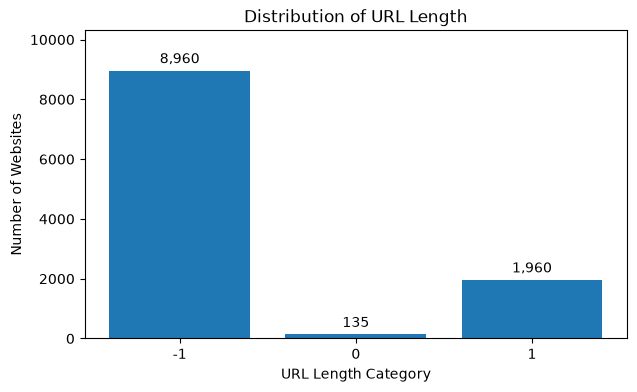

In [ ]:
# Distribution of URL_Length

counts = df.group_by("URL_Length").len().sort("URL_Length")

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in counts["URL_Length"].to_list()],
    counts["len"].to_list()
)

plt.bar_label(bars, labels=[f"{int(v):,}" for v in counts["len"]], padding=3)

plt.title("Distribution of URL Length")
plt.xlabel("URL Length Category")
plt.ylabel("Number of Websites")
plt.margins(y=0.15)
plt.show()

#### The distribution of URL_Length is heavily concentrated at -1, with 8,960 websites falling into this category. Meanwhile, 1,960 websites have a value of 1, and only 135 have a value of 0. The mode is -1, and the distribution is very unbalanced, with significantly more websites having phishing-associated URL lengths than legitimate or suspicious ones. This is interesting for our research question because it suggests that URL length characteristics associated with phishing are fairly common across the dataset, although this doesn't necessarily mean all those websites are actually phishing.

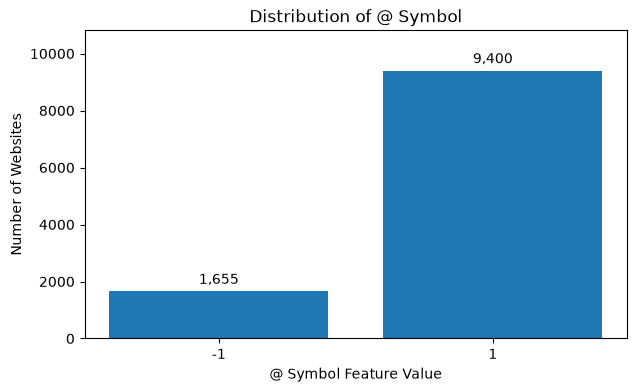

In [ ]:

# Distribution of having_At_Symbol

values = [-1, 1]
counts = [df.filter(pl.col("having_At_Symbol") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of @ Symbol")
plt.xlabel("@ Symbol Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of having_At_Symbol is heavily concentrated at 1, with 9,400 websites in this category compared to only 1,655 at -1. The mode is 1, meaning the majority of websites do not have an @ symbol in their URL. This feature is intentionally binary, meaning it only allows values of -1 and 1, so there is no 0 (suspicious) category. The distribution is very unbalanced, with websites that don't have an @ symbol appearing much more frequently than those that do. Overall, this shows that using an @ symbol in a URL is relatively uncommon in this dataset.

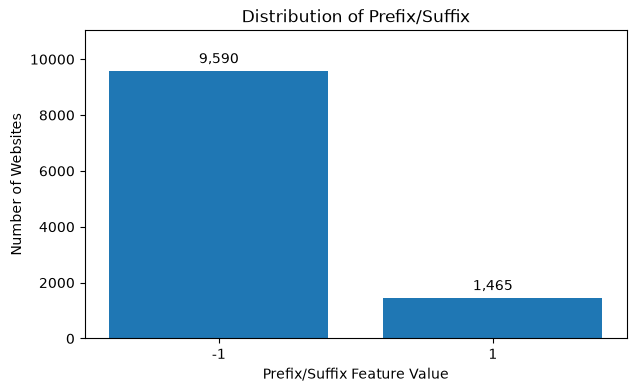

In [ ]:
# Distribution of Prefix_Suffix

values = [-1, 1]
counts = [df.filter(pl.col("Prefix_Suffix") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of Prefix/Suffix")
plt.xlabel("Prefix/Suffix Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of Prefix_Suffix is heavily concentrated at -1, with 9,590 websites in this category compared to 1,465 at 1. The mode is -1, meaning most websites have the phishing-associated value for this feature. Like having_At_Symbol, this is a binary feature that only allows -1 and 1, so there is no 0 category. The distribution is highly unbalanced, with the -1 category appearing much more frequently. This feature is relevant to our research question because prefixes and suffixes separated by hyphens can be used to make domain names appear similar to legitimate websites.

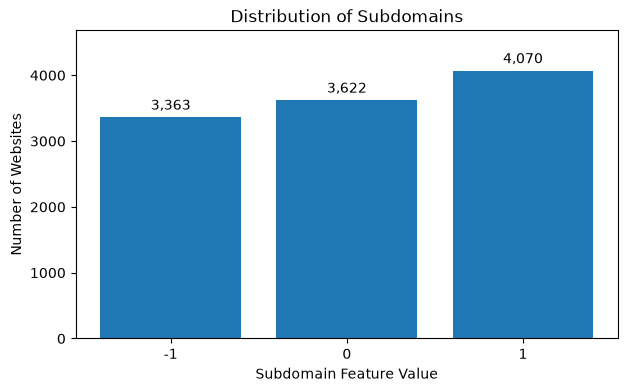

In [ ]:
# Distribution of having_Sub_Domain

values = [-1, 0, 1]
counts = [df.filter(pl.col("having_Sub_Domain") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of Subdomains")
plt.xlabel("Subdomain Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of having_Sub_Domain is relatively balanced compared to the other features. There are 3,363 websites with a value of -1, 3,622 with a value of 0, and 4,070 with a value of 1. The mode is 1, although all three categories appear fairly frequently. Unlike some of the binary features, this feature includes a suspicious (0) category. There is no single category that heavily dominates the distribution, and traditional skewness and numerical outliers don't apply because the values are categorical. This is interesting because it shows that websites in the dataset have a variety of subdomain characteristics, which could be useful to investigate when looking at how phishing URLs attempt to appear legitimate.

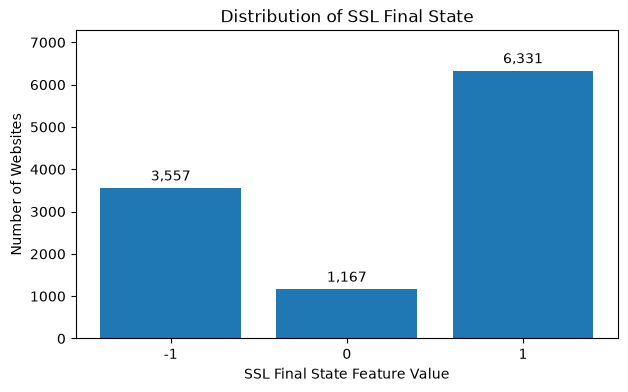

In [ ]:
# Distribution of SSLfinal_State

values = [-1, 0, 1]
counts = [df.filter(pl.col("SSLfinal_State") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of SSL Final State")
plt.xlabel("SSL Final State Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()


#### The distribution of SSLfinal_State is concentrated at 1, with 6,331 websites in this category. There are also 3,557 websites with a value of -1 and 1,167 with a value of 0. The mode is 1, meaning legitimate-associated SSL characteristics are the most common. The distribution is unbalanced, with the suspicious category appearing the least frequently. This feature is particularly relevant to our research question because HTTPS and SSL certificates can influence how trustworthy a website appears, although having HTTPS alone does not guarantee that a website is legitimate.

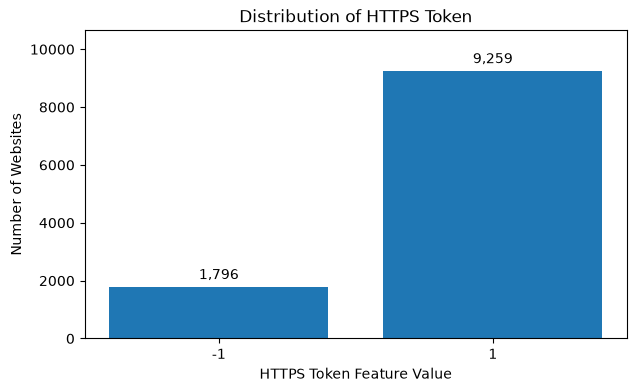

In [ ]:
# Distribution of HTTPS_token

values = [-1, 1]
counts = [df.filter(pl.col("HTTPS_token") == v).height for v in values]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    [str(v) for v in values],
    counts
)

plt.bar_label(bars, labels=[f"{v:,}" for v in counts], padding=3)

plt.title("Distribution of HTTPS Token")
plt.xlabel("HTTPS Token Feature Value")
plt.ylabel("Number of Websites")

plt.margins(y=0.15)

plt.show()

#### The distribution of HTTPS_token is heavily concentrated at 1, with 9,259 websites in this category compared to 1,796 at -1. The mode is 1, meaning most websites do not exhibit the phishing-associated HTTPS token characteristic. This feature is binary, so it only allows values of -1 and 1, with no 0 category. The distribution is unbalanced. This is relevant to our research question because attackers may include the word "HTTPS" in a domain name to make a website appear secure, even when it isn't legitimate.

## Relationships

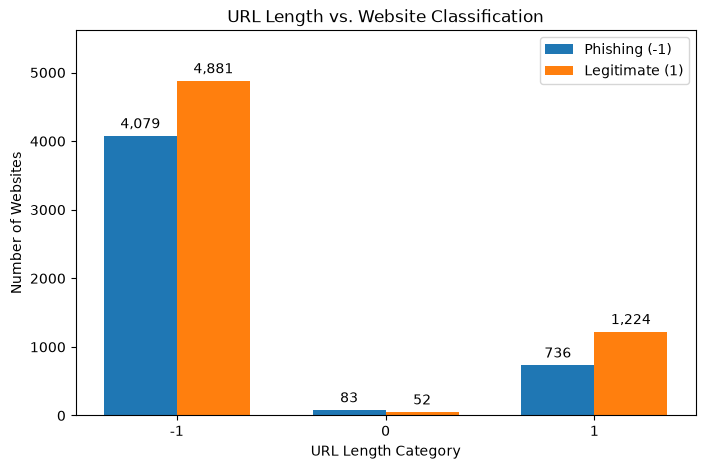

In [ ]:
# Plot 1 - Relationship between URL_Lengh and Result

counts = (
    df.group_by(["URL_Length", "Result"])
    .len()
    .sort(["URL_Length", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("URL_Length") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("URL_Length") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

import numpy as np

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("URL Length vs. Website Classification")
plt.xlabel("URL Length Category")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

In [ ]:
df.group_by("URL_Length").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("URL_Length")

URL_Length,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,8960,4079,45.52
0,135,83,61.48
1,1960,736,37.55


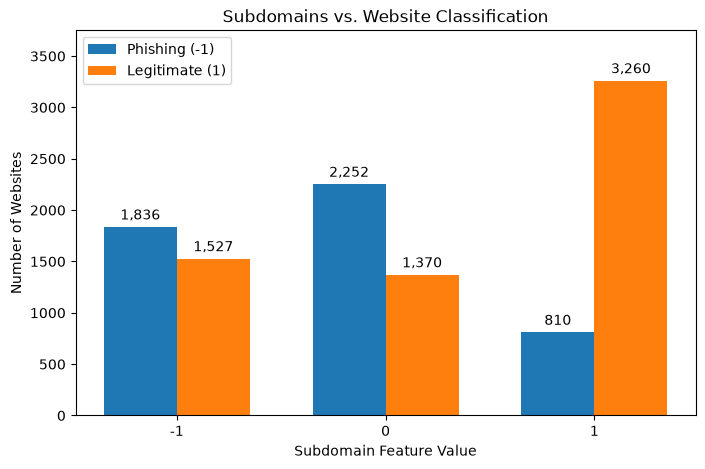

In [ ]:
# Plot 2 - Relationship between having_Sub_Domain and Result

counts = (
    df.group_by(["having_Sub_Domain", "Result"])
    .len()
    .sort(["having_Sub_Domain", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("having_Sub_Domain") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("having_Sub_Domain") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("Subdomains vs. Website Classification")
plt.xlabel("Subdomain Feature Value")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()


**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

In [ ]:
df.group_by("having_Sub_Domain").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("having_Sub_Domain")

having_Sub_Domain,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,3363,1836,54.59
0,3622,2252,62.18
1,4070,810,19.9


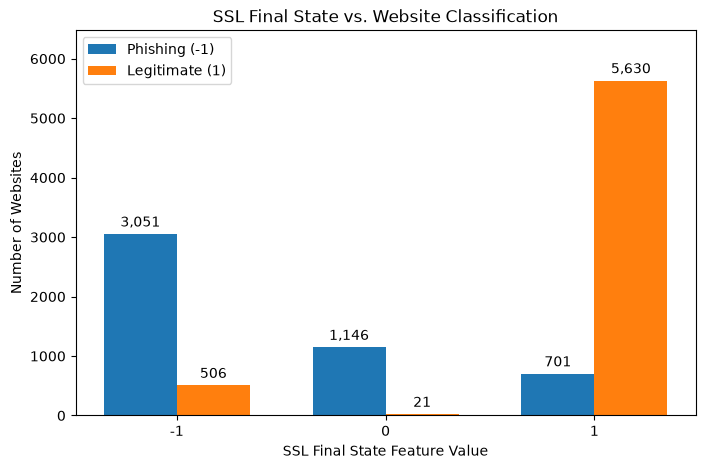

In [ ]:
# Plot 3 - Relationship between SSLfinal_State and Result

counts = (
    df.group_by(["SSLfinal_State", "Result"])
    .len()
    .sort(["SSLfinal_State", "Result"])
)

values = [-1, 0, 1]

phishing_counts = [
    counts.filter(
        (pl.col("SSLfinal_State") == v) & (pl.col("Result") == -1)
    )["len"].sum()
    for v in values
]

legitimate_counts = [
    counts.filter(
        (pl.col("SSLfinal_State") == v) & (pl.col("Result") == 1)
    )["len"].sum()
    for v in values
]

x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, phishing_counts, width, label="Phishing (-1)")
bars2 = plt.bar(x + width/2, legitimate_counts, width, label="Legitimate (1)")

plt.bar_label(bars1, labels=[f"{v:,}" for v in phishing_counts], padding=3)
plt.bar_label(bars2, labels=[f"{v:,}" for v in legitimate_counts], padding=3)

plt.xticks(x, [str(v) for v in values])
plt.title("SSL Final State vs. Website Classification")
plt.xlabel("SSL Final State Feature Value")
plt.ylabel("Number of Websites")
plt.legend()

plt.margins(y=0.15)
plt.show()


**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

In [ ]:
df.group_by("SSLfinal_State").agg(
    pl.len().alias("Total Websites"),
    (pl.col("Result") == -1).sum().alias("Phishing Websites"),
    ((pl.col("Result") == -1).mean() * 100)
        .round(2)
        .alias("Phishing Percentage")
).sort("SSLfinal_State")

SSLfinal_State,Total Websites,Phishing Websites,Phishing Percentage
i64,u32,u32,f64
-1,3557,3051,85.77
0,1167,1146,98.2
1,6331,701,11.07


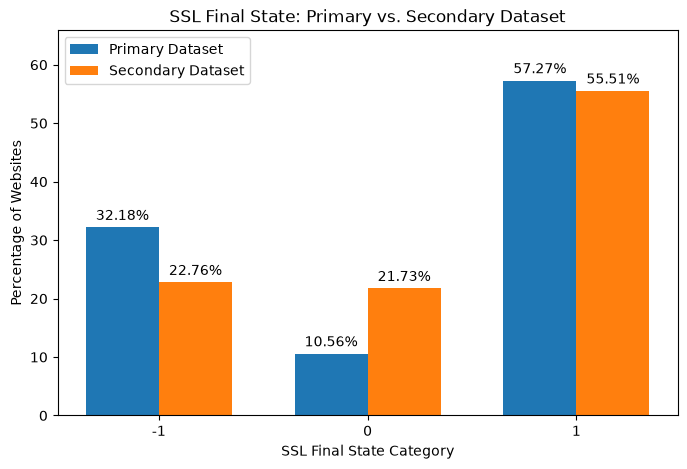

In [ ]:
# Load the secondary dataset
with open("../datasets/website-phishing/PhishingData.arff", "r") as file:
    dataset2 = arff.load(file)

# Create the Polars DataFrame for the secondary dataset
column_names2 = [attribute[0] for attribute in dataset2["attributes"]]

df_secondary = pl.DataFrame(
    dataset2["data"],
    schema=column_names2,
    orient="row"
)

# Convert SSLfinal_State to an integer
df_secondary = df_secondary.with_columns(
    pl.col("SSLfinal_State").cast(pl.Int64)
)

# Compare SSLfinal_State across both datasets
values = [-1, 0, 1]

primary_percentages = [
    df.filter(pl.col("SSLfinal_State") == v).height / df.height * 100
    for v in values
]

secondary_percentages = [
    df_secondary.filter(pl.col("SSLfinal_State") == v).height / df_secondary.height * 100
    for v in values
]

# Set up the bar chart
x = np.arange(len(values))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    primary_percentages,
    width,
    label="Primary Dataset"
)

bars2 = plt.bar(
    x + width/2,
    secondary_percentages,
    width,
    label="Secondary Dataset"
)

# Display percentages above each bar
plt.bar_label(
    bars1,
    labels=[f"{v:.2f}%" for v in primary_percentages],
    padding=3
)

plt.bar_label(
    bars2,
    labels=[f"{v:.2f}%" for v in secondary_percentages],
    padding=3
)

plt.xticks(x, [str(v) for v in values])
plt.title("SSL Final State: Primary vs. Secondary Dataset")
plt.xlabel("SSL Final State Category")
plt.ylabel("Percentage of Websites")
plt.legend()

plt.margins(y=0.15)

plt.show()


### So what and what's next ? 
##### What each plot shows and why it matters for our research question. 

# Plot 1 – URL Length vs. Website Classification 

#### Looking at `URL_Length` compared to `Result`, the -1 category had the largest number of phishing websites (4,079), but the 0 category actually had the highest percentage of phishing websites at 61.48%. Meanwhile, 45.52% of websites whose URL lengths were categorized as phishing-associated (-1) were actually phishing, compared to 37.55% of websites whose URL lengths were categorized as legitimate-associated (1). This was somewhat unexpected because I thought the phishing-associated URL length category (-1) would have the highest phishing percentage. It's also interesting that 736 websites with legitimate-associated URL lengths were still classified as phishing. This matters to our research question because it shows that phishing websites can have normal-looking URL lengths, so URL length alone isn't enough to determine whether a website is phishing.

##### This makes me wonder whether phishing websites with normal-looking URL lengths also have other legitimate-looking characteristics, such as legitimate-associated SSL characteristics or simpler subdomain structures. A next step could be to compare URL_Length with SSLfinal_State or having_Sub_Domain, specifically among websites where Result = -1, to see whether multiple legitimate-looking characteristics appear together.

# Plot 2 - Subdomains vs. Website Classification

#### Looking at `having_Sub_Domain` compared to `Result`, the 0 category had the highest percentage of phishing websites at 62.18%, followed by the -1 category at 54.59%. Meanwhile, only 19.90% of websites with a value of 1 were phishing. Personally I think this is somewhat unexpected because I would have thought the -1 category would have the highest percentage of phishing websites rather than the suspicious (0) category. It's also interesting that 810 websites with legitimate-associated subdomain characteristics were still classified as phishing. This matters to our research question because it shows that phishing websites don't necessarily need suspicious-looking subdomains, and some may have simpler domain structures that appear legitimate. 

#### This makes me wonder whether phishing websites with normal-looking subdomains also have other legitimate-looking characteristics, such as a normal URL length or trusted SSL certificates. We could specifically look at phishing websites with having_Sub_Domain = 1 and compare their other features to see what characteristics they share.

# Plot 3 - SSL Final State vs. Website Classification

#### Looking at SSLfinal_State compared to Result, the 0 category had the highest percentage of phishing websites at 98.20%, followed by the -1 category at 85.77%. Meanwhile, only 11.07% of websites with a value of 1 were phishing. It makes sense that websites with legitimate-associated SSL characteristics have a much lower phishing percentage. What's especially interesting is that 701 phishing websites still had an SSLfinal_State value of 1. This matters to our research question because it suggests that phishing websites can have SSL characteristics associated with legitimate websites, meaning security indicators alone aren't enough to determine whether a website is phishing. A next step would be to investigate whether these websites also have normal-looking URL lengths, simple subdomain structures, or other characteristics that could make them appear legitimate. It would also be interesting to investigate how often phishing websites have multiple legitimate-associated features at the same time. How many of these features (like url_length, @ symbol, SSL final state, etc) are usually used together in order to carry out a successfull phishing attempt? I'm assuming too many of these features would make it look too suspicious for someone to click. Is there a sweet spot? 

# Plot 4 - SSL Final State: Primary vs. Secondary Dataset

#### Comparing SSLfinal_State across both datasets, the most common category in both is 1 (legitimate), with 57.27% of websites in the primary dataset and 55.51% in the secondary dataset falling into this category. However, the secondary dataset has a higher percentage of websites with a value of 0 (21.73%) compared to the primary dataset (10.56%). Meanwhile, the primary dataset has more websites with a value of -1 (32.18%) compared to the secondary dataset (22.76%). I thought the distributions might be more similar since both datasets include phishing-related website features, so the differences were somewhat unexpected. This matters to our research question because it shows how frequently different SSL characteristics appear in two separate datasets, although it doesn't tell us whether websites with these characteristics are actually phishing or whether people would find them convincing. It would be interesting to see whether the proportion of phishing websites with these characteristics is similar across both datasets. This could help us better understand whether SSL characteristics are useful for distinguishing phishing websites from legitimate ones, or whether phishing websites frequently share security characteristics with legitimate websites.

### Does our original research question (Which features of phishing links and webpages make them harder for people to recognize?) need to be changed? 

##### I think our question does need to be revised. I don't think the direction needs to change but some revision would help. Our original question was worded in a way that makes it seem like we want to test/measure people's ability on recognizing phishing websites/urls. But neither this dataset nor our other primary and secondary datasets actually measure that, so I don't think we can answer that question directly.

#### Through this analysis I found that some phishing websites still have features typically associated with legitimate websites, such as normal-looking URL lengths, subdomain structures, and SSL characteristics. With this analysis I think that instead of focusing on whether people can recognize phishing websites, we should focus on the characteristics that phishing and legitimate websites have in common! We could change our questoin to "Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?" 

## Checkpoint Three

The cells below are retained from the original notebook and executed in this combined analysis.

## Follow-up Exploratory Analysis

For this checkpoint, I'll be looking at a few follow-up questions that came up from the earlier analysis. First, I want to see whether the relationship between IP address usage and phishing looks similar across our two datasets. Then, I want to look more closely at whether phishing and legitimate URLs differ in how many special characters they contain. These are exploratory comparisons, so I am mainly looking for patterns in the data.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff

Matplotlib is building the font cache; this may take a moment.


In [ ]:
# Load the primary PhiUSIIL dataset

primary_path = Path("../datasets/PhiUSIIL_Phishing_URL_Dataset.csv")

if not primary_path.exists():
    primary_path = Path("datasets/PhiUSIIL_Phishing_URL_Dataset.csv")

primary_df = pd.read_csv(primary_path)


# Load the Website Phishing dataset

secondary_path = Path("../datasets/website-phishing/PhishingData.arff")

if not secondary_path.exists():
    secondary_path = Path("datasets/website-phishing/PhishingData.arff")

data, metadata = arff.loadarff(secondary_path)

secondary_df = pd.DataFrame(data)

# convert the ARFF byte strings into normal strings
for col in secondary_df.select_dtypes(include=["object"]).columns:
    secondary_df[col] = secondary_df[col].str.decode("utf-8")

#convert the coded features to integers
secondary_df = secondary_df.astype(int)


print("Primary dataset shape:", primary_df.shape)
print("Secondary dataset shape:", secondary_df.shape)

Primary dataset shape: (235795, 56)
Secondary dataset shape: (1353, 10)


### 1. IP Address Feature Across Both Datasets

The secondary analysis showed that the IP address feature may be related to phishing classification, so I wanted to see whether a similar pattern appears in the primary dataset.

The primary dataset only has phishing and legitimate classifications, while the secondary dataset also has a suspicious category. For this comparison, I will leave out the suspicious category so that both datasets are comparing phishing and legitimate websites.

In [ ]:
# Keep only phishing and legitimate rows in the secondary dataset
secondary_binary = secondary_df[
    secondary_df["Result"].isin([-1, 1])
].copy()


# phishing rate by IP feature in the primary dataset
primary_ip = (
    primary_df.groupby("IsDomainIP")["label"]
    .apply(lambda x: (x == 0).mean() * 100)
    .reset_index(name="phishing_rate")
)

primary_ip["dataset"] = "PhiUSIIL"
primary_ip = primary_ip.rename(columns={"IsDomainIP": "ip_feature"})


#phishing rate by IP feature in the secondary dataset
secondary_ip = (
    secondary_binary.groupby("having_IP_Address")["Result"]
    .apply(lambda x: (x == -1).mean() * 100)
    .reset_index(name="phishing_rate")
)

secondary_ip["dataset"] = "Website Phishing"
secondary_ip = secondary_ip.rename(
    columns={"having_IP_Address": "ip_feature"}
)


#combine the summaries so they are easier to compare
ip_compare = pd.concat(
    [primary_ip, secondary_ip],
    ignore_index=True
)

display(ip_compare)

,ip_feature,phishing_rate,dataset
0,0,42.655332,PhiUSIIL
1,1,100.000000,PhiUSIIL
2,0,55.054152,Website Phishing
3,1,64.788732,Website Phishing


The table above gives the phishing percentage for each IP address feature value. A bar chart makes it easier to compare the pattern across the two datasets.

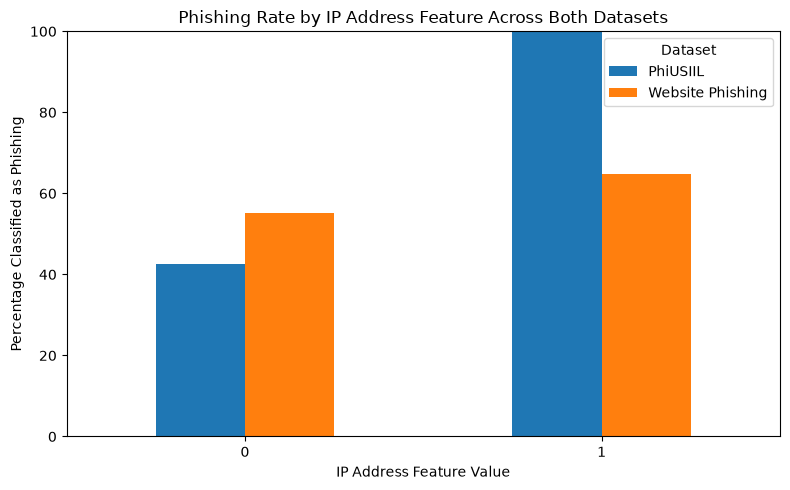

In [ ]:
ip_plot = ip_compare.pivot(
    index="ip_feature",
    columns="dataset",
    values="phishing_rate"
)

ax = ip_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Phishing Rate by IP Address Feature Across Both Datasets")
plt.xlabel("IP Address Feature Value")
plt.ylabel("Percentage Classified as Phishing")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

**Plot note.** This visualization summarizes the relationship described in the preceding table or code. Compare the groups by their proportions, centers, or distributions rather than by raw counts alone when dataset sizes differ.

In [ ]:
print("PhiUSIIL IP feature counts:")
display(
    primary_df["IsDomainIP"]
    .value_counts()
    .sort_index()
)

print("Website Phishing IP feature counts:")
display(
    secondary_binary["having_IP_Address"]
    .value_counts()
    .sort_index()
)

PhiUSIIL IP feature counts:


IsDomainIP
0    235157
1       638
Name: count, dtype: int64

Website Phishing IP feature counts:


having_IP_Address
0    1108
1     142
Name: count, dtype: int64

#### What I noticed

Both datasets show a higher phishing rate when the IP address feature has a value of 1. In the PhiUSIIL dataset, about 43% of websites with `IsDomainIP = 0` are phishing, while 100% of websites with `IsDomainIP = 1` are phishing. However, there are only 638 websites with a value of 1 compared with 235,157 with a value of 0, so IP-based domains are very uncommon in this dataset.

The Website Phishing dataset shows the same general direction, but the difference is smaller. About 55% of websites with an IP feature value of 0 are phishing compared with about 65% when the value is 1.

#### So what?

It was interesting that both datasets showed a higher phishing rate for the IP address feature even though the size of the difference was not the same. At the same time, the PhiUSIIL result shows why it is important to look at counts along with percentages. The 100% phishing rate sounds very strong, but it comes from only 638 websites out of more than 235,000. This means the feature may be related to phishing, but it would not identify most phishing websites by itself.

#### What next?

A next step could be to see whether this pattern changes when the IP address feature is considered along with another characteristic, such as HTTPS or URL length. It would also be helpful to check the documentation for both datasets to make sure `IsDomainIP` and `having_IP_Address` represent the same idea before making a stronger comparison between them.


### 2. Special Characters in Phishing and Legitimate URLs

Next, I wanted to look more closely at the special-character ratio in URLs. The earlier analysis showed the overall distribution of this feature, but I wanted to directly compare phishing and legitimate websites. The `SpacialCharRatioInURL` column represents the proportion of special characters in each URL. I will compare this feature between phishing and legitimate URLs to see whether one group tends to have a higher ratio.

,count,mean,median,std,min,max
Phishing (0),100945,0.083,0.080,0.036,0.005,0.397
Legitimate (1),134850,0.048,0.042,0.019,0.000,0.231


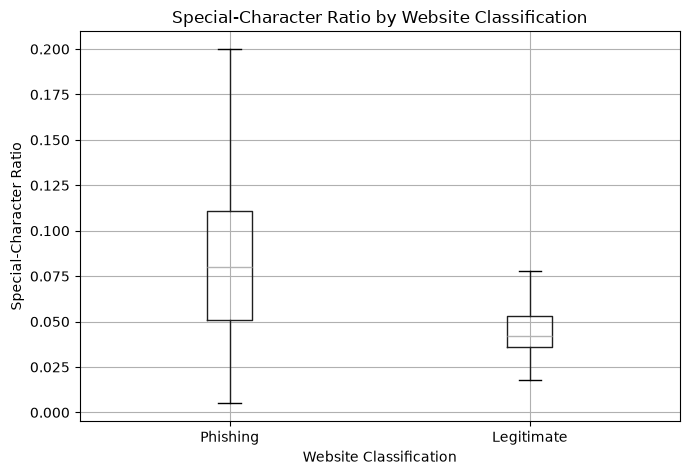

In [ ]:
#The table gives a quick summary of the two groups. I also used a box plot so I could compare their centers and spreads more easily:

special_stats = (
    primary_df.groupby("label")["SpacialCharRatioInURL"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

special_stats.index = [
    "Phishing (0)",
    "Legitimate (1)"
]

display(special_stats.round(3))

primary_df.boxplot(
    column="SpacialCharRatioInURL",
    by="label",
    figsize=(7, 5),
    showfliers=False
)

plt.suptitle("")
plt.title("Special-Character Ratio by Website Classification")
plt.xlabel("Website Classification")
plt.ylabel("Special-Character Ratio")
plt.xticks(
    [1, 2],
    ["Phishing", "Legitimate"]
)

plt.tight_layout()
plt.show()

#### What I noticed

Phishing URLs generally have a higher special-character ratio than legitimate URLs. The median for phishing URLs is about 0.080, compared with about 0.042 for legitimate URLs. The phishing group also has a wider spread, which means there is more variation in the amount of special characters used.

The box plot shows a clear difference between the two groups, although there is still some overlap. This means special-character ratio may be related to phishing classification, but it cant separate every phishing URL from every legitimate URL.

#### So what?

This was a useful pattern because special characters are something that can actually appear directly in a URL and may make the URL look more unusual. At the same time, the overlap between the groups shows that this feature would not be enough by itself to decide whether a website is phishing. Some legitimate URLs also have higher special-character ratios, and some phishing URLs have lower ratios.

#### What next?

A next step could be to see whether the special-character ratio is still different between phishing and legitimate URLs when the URLs are around the same length. Since phishing URLs also tended to be longer, URL length could be related to part of the difference we are seeing here.

Another possible comparison would be to look at special-character ratios only among HTTPS websites.

### 3. Special-Character Ratio Within URL Length Groups

The previous analysis showed that phishing URLs tend to have higher special-character ratios than legitimate URLs. We also already know from the earlier group analysis that phishing URLs tend to be longer.

I wanted to check whether the difference in special-character ratio still appears when URLs are compared within similar length groups. I divided the URLs into short, medium, and long groups and compared phishing and legitimate websites within each group.

In [ ]:
# Create simple URL length groups
primary_df["length_group"] = pd.cut(
    primary_df["URLLength"],
    bins=[0, 25, 40, float("inf")],
    labels=["Short (25 or less)", "Medium (26-40)", "Long (41+)"]
)

# Check how many phishing and legitimate URLs are in each group
length_counts = pd.crosstab(
    primary_df["length_group"],
    primary_df["label"]
)

length_counts.columns = ["Phishing", "Legitimate"]

display(length_counts)

,Phishing,Legitimate
length_group,,
Short (25 or less),24712,63992
Medium (26-40),40167,70060
Long (41+),36066,798


In [ ]:
#Check the number of phishing and legitimate URLs in each length group so that we can see whether any of the groups were very small before comparing their special-character ratios.

length_special_stats = (
    primary_df.groupby(
        ["length_group", "label"],
        observed=True
    )["SpacialCharRatioInURL"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

length_special_stats["classification"] = (
    length_special_stats["label"]
    .map({
        0: "Phishing",
        1: "Legitimate"
    })
)

display(
    length_special_stats[
        ["length_group", "classification", "count", "mean", "median"]
    ].round(3)
)

,length_group,classification,count,mean,median
0,Short (25 or less),Phishing,24712,0.064,0.050
1,Short (25 or less),Legitimate,63992,0.053,0.045
2,Medium (26-40),Phishing,40167,0.081,0.077
3,Medium (26-40),Legitimate,70060,0.044,0.036
4,Long (41+),Phishing,36066,0.098,0.101
5,Long (41+),Legitimate,798,0.042,0.024


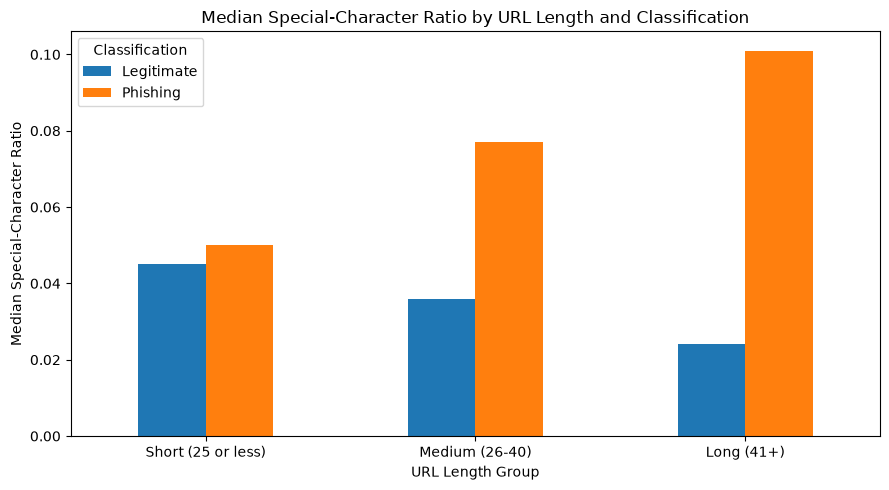

In [ ]:
median_plot = (
    length_special_stats
    .pivot(
        index="length_group",
        columns="classification",
        values="median"
    )
)

ax = median_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Median Special-Character Ratio by URL Length and Classification")
plt.xlabel("URL Length Group")
plt.ylabel("Median Special-Character Ratio")
plt.xticks(rotation=0)
plt.legend(title="Classification")

plt.tight_layout()
plt.show()

#### What I noticed

The difference in special-character ratio still appears even when I compare URLs within similar length groups. For short URLs, the phishing and legitimate groups are fairly close, with median ratios of about 0.050 and 0.045. The difference becomes much larger for medium URLs, where the phishing median is about 0.077 compared with 0.036 for legitimate URLs. For long URLs, the difference is even larger, with a phishing median of about 0.101 compared with 0.024 for legitimate URLs.

One thing that stood out is that the long URL group is very unbalanced. There are 36,066 phishing URLs but only 798 legitimate URLs in that group, so that comparison should be interpreted carefully.

#### So what?

This suggests that the higher special-character ratio among phishing URLs is not only happening because phishing URLs tend to be longer. Even within the same general length groups, phishing URLs usually have higher special-character ratios. The pattern is weakest for short URLs and becomes stronger for medium and long URLs. This could mean that unusual URL structure becomes more noticeable among longer phishing URLs, although this analysis only shows an association and does not explain why the pattern happens.

### What's next?

A next step could be to look more closely at which kinds of special characters are creating this difference. It could also be useful to compare medium-length URLs more closely because both phishing and legitimate websites have many observations in that group, making it a more balanced comparison than the long URL group.

#### Most notable findings from this EDA:

1) Both datasets showed a higher phishing rate when the IP address feature had a value of 1, although the pattern was much stronger in PhiUSIIL. Looking at the counts also showed that IP-based domains were very rare, so the feature would not identify most phishing websites by itself.

2) Phishing URLs generally had higher special-character ratios than legitimate URLs. This difference was still visible when URLs were split into short, medium, and long groups, so the pattern does not seem to come only from phishing URLs being longer.
